---
title: "The Weisz-Prater criterion: what an observed rate can tell you"
description: "One inequality in measurable quantities decides whether a rate is kinetics or diffusion. This page computes what its threshold actually guarantees, tests the non-isothermal extension against a false-negative map, and finds the corner of the authors' own parameter range where their claim that the observable removes the multiplicity stops holding."
categories: [sec:B, struct:S3, tier:T0, data:tier6, phase:gas-solid]
date: 2026-08-01
---

# The Weisz-Prater criterion: what an observed rate can tell you

**Catalog ID:** `B1.4` · **Structures:** `S3` (1D steady BVP) · **Tier:** T0

Every other pellet page in this gallery runs the problem **forwards**: you know
the rate constant, you compute the effectiveness factor. An experimenter cannot
do that. They have a measured rate, a particle size, a concentration and a
diffusivity, and the question they need answered is whether the number they just
measured is chemistry or transport, *before* they know any kinetics at all.

The Weisz-Prater criterion answers it with one inequality in observables only:

$$\Phi \;=\; \frac{\mathrm{d}N/\mathrm{d}t}{c_0}\,\frac{R^2}{D} \;<\; 1 .$$

That is the inverse problem, and it is the whole content of this page. Three
things are done with it:

1. **What does the threshold actually guarantee?** The sources state it at
   order of magnitude. Here $\eta$ at $\Phi = 1$ is computed exactly, and it
   depends strongly on shape and on kinetics.
2. **Where does it fail?** A false-negative map over $\phi_0$, $\beta$ and
   $\gamma$, comparing the isothermal criterion with Weisz and Hicks' own
   non-isothermal extension, their eq. (10a).
3. **Does the observable really remove the multiplicity?** Weisz and Hicks state
   that it does. Over most of their range it does. Where it does not is located
   here, and it reaches **one of the curves their own Fig. 7 plots**.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "main"  # replaced by the release tag at publication
PYMRM = ">=3.3.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "B1.4-weisz-prater-criterion"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy.integrate import quad
from scipy.optimize import brentq
from pymrm import construct_grad
from gallery_utils import Claims
from model import (NU, Power, InhibitedLH, WeiszHicks, Pellet, shoot,  # this page's model.py
                   Branch, fold_depth, turning_points, max_log_slope, fold_onset, phi0_eq10,
                   Phi_c_eq10a, threshold_exact, eta_exact, q_ratio)

np.seterr(all="ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])
BREAK = []


def brk(row, metric, broken):
    """One injected defect: ``broken`` is what claim ``metric`` becomes with it."""
    caught = claims.breaks(row, metric, broken)
    BREAK.append((row, metric, claims[metric], broken, caught))
    return caught

## Background

A porous catalyst pellet consumes reactant faster than diffusion can supply it,
so the interior sees less than the surface concentration and the *observed* rate
falls below the intrinsic one. The ratio is the effectiveness factor $\eta$, and
the classical route to it, Thiele's, needs the intrinsic rate constant $k$,
through the Thiele modulus $\phi_0 = R\sqrt{k/D}$.

That is exactly backwards for an experimenter. As Weisz and Hicks put it, the
investigator "is in fact faced with the problem as to whether his catalyst
system reflects true kinetic behaviour": $k$ is what they are trying to measure,
so it cannot be an input to the test of whether the measurement is valid.

The way out is that the *product* $\phi_0^2\eta$ contains no rate constant. It is

$$\phi_0^2\,\eta \;=\; \frac{R^2k}{D}\cdot\frac{\text{observed rate}}{kc_0}
\;=\; \frac{\mathrm{d}N/\mathrm{d}t}{c_0}\,\frac{R^2}{D} \;\equiv\; \Phi ,$$

the observed rate per unit particle volume, the particle radius, the bulk
concentration and the effective diffusivity: four things a laboratory can
measure. Requiring $\Phi < 1$ is then a test that presupposes nothing about the
kinetics.

**What it is not is exact.** It is a statement about a *mapping*, measured
$\Phi$ to unknown $\eta$, asserted at order of magnitude. Two questions follow
and neither is answered in the sources: how far from 1 can $\eta$ be while
$\Phi < 1$ still holds, and is $\eta$ even a function of $\Phi$? This page
answers both by sweeping the forward problem and asking what the criterion would
have concluded.

## The published model

### Provenance: what was read, and what was not

**Weisz and Prater (1954), *Advances in Catalysis* 6, 143, is not on disk and
has no open-access route.** It is a book chapter that predates DOIs. It is cited
here as the origin of the result, exactly as Weisz and Hicks' own reference list
gives it on journal page 274, with no chapter title, which is why none appears
anywhere on this page:

> [5] WEISZ P. B. and PRATER C. D., in *Advances in Catalysis*. Vol. 6, p. 143.
> Academic Press, New York 1954.

Everything transcribed below comes instead from **Weisz and Hicks (1962)**,
which is on disk and is also the source of
[`B1.1`/`B1.5`](../B1.1-thiele-weisz-hicks/) and
[`B1.6`](../B1.6-prater-relation/). That paper prints the criterion as its
**eq. (1)**, states its purpose, devotes its **Section V** to the observable
formulation, extends it to the exothermic case as its **eq. (10a)**, and tests
it against its own Fig. 2. Every equation below was read off a 600 dpi render
(`pdftoppm -r 600 -f N -l N -png`) of the journal page named, because the scan's
text layer mangles equations: it renders eq. (1) as `$:$<I` and eq. (10a) as
`expCrBK1 + LOI`.

### An attribution the page has to be honest about

The inequality is universally called the *Weisz-Prater criterion*. Weisz and
Hicks do not attribute it to reference [5]. They write, on journal page 265:

> It was shown by WEISZ [9] that the conditions … offer a useful and general
> order of magnitude criterion

and their [9] is **WEISZ P. B., *Z. Phys. Chem.* 1957 **11** 1**, Weisz alone,
three years after the review. Reference [5], Weisz and Prater 1954, *is* named
and used in this paper, for two other things: the insensitivity of $\eta(\phi)$
to particle shape, and the Arrhenius-slope relation reproduced below. So the
catalogue's citation is kept (the criterion carries both names in the
literature, and Weisz and Prater is the origin the case names), and the 1957
attribution Weisz and Hicks themselves give is recorded beside it. Neither 1954
nor 1957 was consulted.

### The equations, as printed

Journal page 265, eq. (1), with $\mathrm{d}N/\mathrm{d}t$ "the reaction rate per
unit volume of a porous catalyst", $c_0$ the concentration "known externally of
the particle", $D$ the effective diffusivity and $R$ the radius:

$$\frac{\mathrm{d}N}{\mathrm{d}t}\,\frac{1}{c_0}\,\frac{R^2}{D} \;<\; 1 \tag{1}$$

Journal page 269 names the group, and the Fig. 7 caption on page 272 repeats it:

$$\eta\phi_0^2 \;=\; \frac{\mathrm{d}N}{\mathrm{d}t}\,\frac{1}{c_0}\,\frac{R^2}{D}
\;=\; \Phi \tag{11}$$

The pellet itself is their eq. (9), journal page 267, written for the sphere:

$$\frac{\mathrm{d}^2y}{\mathrm{d}x^2} + \frac{2}{x}\frac{\mathrm{d}y}{\mathrm{d}x}
= \phi_0^2\,y\,\exp\!\left(\gamma\beta\,\frac{1-y}{1+\beta(1-y)}\right), \tag{9}$$

"where $\phi_0 = R\sqrt{(k_0/D)}$; $y = c/c_0$; $x = r/R$", subject to
"$y(1) = 1$, $(\mathrm{d}y/\mathrm{d}x)_{x=0} = 0$".

For an exothermic reaction the criterion is tightened. Journal page 269, in
terms of the Thiele modulus:

$$\phi_0^2\exp\!\left[\frac{\gamma\beta}{1+\beta}\right] \le 1,
\qquad\text{or}\qquad
\phi_0 \le \exp\!\left[-\tfrac{1}{2}\frac{\gamma\beta}{1+\beta}\right] \tag{10}$$

and then, "reformulated in terms of *observables* by eliminating $k_0$", the
same page gives the form this page is about:

$$\frac{\mathrm{d}N}{\mathrm{d}t}\,\frac{1}{c_0}\,\frac{R^2}{D}\,
\exp\!\left[\frac{\gamma\beta}{1+\beta}\right] \;<\; 1. \tag{10a}$$

Two further printed statements are used as checks rather than as inputs.
Journal page 268, attributed to WEISZ [5], that is to Weisz and Prater 1954:

$$\frac{Q'}{Q} = 1 + \frac{1}{2}\frac{\mathrm{d}\ln\eta}{\mathrm{d}\ln\phi_0},$$

the apparent activation energy an Arrhenius plot returns, which the paper says
ranges between $Q$ and $Q/2$. And journal page 269: "For exothermic reactions,
with severe thermal effects defined by $\beta\gamma \gtrsim 5$, there exists a
region of $\phi_0$-values … where multiple solutions result for
$\eta = \eta(\phi)$."

### The claim this page is built to test

Journal page 273, Section V, quoted in full so the hedge is not lost:

> The transformation of the abscissa to $\eta\phi_0^2$ has removed the
> multiplicity in the functions, in the sense that a given *observed rate* …
> defines the system uniquely. However, there will be a metastable region of
> rates, indicated by the dashed portions between arrows, which corresponds to
> the regions of multiple solutions in $\eta$ vs. $\phi_0$, which we believe
> cannot be realized by the steady-state catalytic system.

That is a strong, falsifiable statement about a mapping, and it is the reason
the criterion can be used at all: if two different pellet states could produce
the same $\Phi$, no threshold on $\Phi$ could decide between them. The hedge is
about *stability*, states they believe are not reachable, not about
uniqueness, and it is uniqueness that the fold section below tests.

Fig. 7 has four panels, $\gamma = 10, 20, 30, 40$, and each carries its own set
of $\beta$ labels. The largest $\beta$ drawn on each is $0.8$, $0.8$, $0.4$ and
$0.3$, read off the printed curve labels on a 600 dpi render of page 272, not
digitised.

## Parameters and assumptions

The pellet model is Weisz and Hicks' eq. (9): the two balances of their
eqs. (4) and (5) reduced to one equation by the Prater relation, which is proved
and tested on [`B1.6`](../B1.6-prater-relation/) and is not re-derived here.
Written for a general geometry index:

$$\nabla^2 y \;=\; \phi_0^2\,\mathcal{R}(y),\qquad
\mathcal{R}(y) = y\,\exp\!\left[\frac{\gamma\beta(1-y)}{1+\beta(1-y)}\right],
\qquad \left.\frac{\partial y}{\partial n}\right|_{u=0}=0,\quad y(1)=1,$$

with $y = c/c_0$, $u$ the position scaled on $R$, $\gamma = Q/(R_gT_0)$ the
Arrhenius number, $\beta = (-\Delta H)Dc_0/(\lambda T_0)$ the Prater number, and
$\nabla^2$ carrying the geometry index $\nu = 0,1,2$ for slab, cylinder and
sphere. Weisz and Hicks solve the sphere; $\nu$ is swept here because the
threshold depends on it.

The effectiveness factor and the observable follow from the same surface flux:

$$\eta = \frac{\nu+1}{\phi_0^2}\left.\frac{\mathrm{d}y}{\mathrm{d}u}\right|_{u=1},
\qquad
\Phi = \phi_0^2\eta = (\nu+1)\left.\frac{\mathrm{d}y}{\mathrm{d}u}\right|_{u=1}.$$

**$\Phi$ does not contain $\phi_0$.** It is the dimensionless surface flux, and a
solver never needs the rate constant to report it, which is the point of the
criterion.

Parameter ranges follow the paper: $\gamma = 10$ to $40$, and $\beta$ from
$-0.8$ (endothermic) to $+0.8$ (exothermic); the sweeps here use
$-0.4 \le \beta \le 0.6$. Assumptions carried without test: steady state, one
reaction, constant $D$ and $\lambda$, no external film, and $\gamma$ held fixed
while $\phi_0$ varies (which is what the printed $Q'/Q$ relation assumes, since
strictly $\gamma = Q/R_gT_0$ also moves with temperature).

Four isothermal rate laws are used besides the paper's first-order one, all
normalised so that $\mathcal{R}(1) = 1$, which keeps $\phi_0^2$ equal to the
surface rate times $R^2/(Dc_0)$ and therefore keeps $\Phi$ exactly the printed
observable in every case:

$$\mathcal{R} = 1,\quad y^{1/2},\quad y,\quad y^2, \quad
\frac{36\,y}{(1+5y)^2}.$$

The last is a strongly inhibited Langmuir-Hinshelwood form: its rate *decreases*
with concentration above $y = 0.2$, which is the one isothermal way to get
$\eta > 1$.

In [3]:
GAMMAS = (10.0, 20.0, 30.0, 40.0)                    # Arrhenius numbers, Fig. 7 panels
BETAS = (-0.4, -0.2, 0.0, 0.1, 0.2, 0.3, 0.4, 0.6)   # Prater numbers of the sweep
KIN = [Power(0), Power(0.5), Power(1), Power(2), InhibitedLH(5.0)]   # R(1) = 1 each
GEOMS = (("slab", 0), ("cylinder", 1), ("sphere", 2))
# largest beta labelled on each panel of Fig. 7 (600 dpi render of page 272)
FIG7_BETA_MAX = {10.0: 0.8, 20.0: 0.8, 30.0: 0.4, 40.0: 0.3}
# measured off the same render, only to judge resolving power (see the fold section):
# panel (d) gridlines Phi = 0.1 and 1000 at x = 199.6 and 1631.3 px (four decades),
# and the printed curve stroke, 6 px at ink threshold 160/255 and 7 px at 200/255
FIG7D_DECADE_PX = (1631.3 - 199.6) / 4.0
FIG7D_STROKE_PX = (6.0, 7.0)

## The data

**There is none, and there does not need to be: provenance tier 6.**

Neither source reports a measurement that this page could be compared against.
Weisz and Hicks (1962) contains no experimental data (the same finding is
recorded for [`B1.1`](../B1.1-thiele-weisz-hicks/) and
[`B1.6`](../B1.6-prater-relation/)), and Weisz and Prater (1954) is a review.
**Nothing on this page is validated against experiment**: what follows is a set
of internal consistency checks, a comparison with exact closed forms, and a
comparison between two independent numerical methods.

No figure is digitised and no CSV is shipped. The criterion is an *inequality
between computable quantities*, so it can be tested by sweeping the forward
problem, and the printed numerical statements used as checks are in the text.
Three things *are* read off the 600 dpi render of Fig. 7 on journal page 272,
and none of them is a data point: the $\beta$ labels printed beside the curves,
the pixel positions of panel (d)'s major gridlines, and the width in pixels of
the printed curve stroke. The last two serve only to ask whether the figure
could have shown a fold this page computes. No curve is traced and no value is
read off an axis, so the tier stays 6.

## PyMRM implementation

Two independent routes to the same pellet, both in `model.py`.

**`Pellet`** is the pymrm finite-volume solver on $u = r/R$. It takes $\phi_0$
and returns the profile, $\eta$ and $\Phi$.

- **Boundary conditions use the OUTWARD normal.** At the centre the outward
  normal points to $-u$, so symmetry is $\partial y/\partial n = 0$
  (`{a: 1, b: 0, d: 0}`); at the surface $y = 1$ is `{a: 0, b: 1, d: 1}`.
- **`nu` in `construct_div` is geometry**: 0 slab, 1 cylinder, 2 sphere.
- **Operators are assembled once** in `__init__`; the residual is
  `lap @ y + lap_bc - phi0**2 R(y)`, layout `(n_u, 1)`.
- **Exact Jacobian.** Every rate law has a closed-form derivative, so the
  source block of the Jacobian is `construct_coefficient_matrix(phi0**2 dR/dy)`.
  `NumJac((n_u, 1))` is kept as an option; the cell below compares the two.
- **`newton(tol=1e-12, stagnation=True, bounds=(0, 1))`**, and a solve that
  does not report success raises. The bounds are physical: the maximum
  principle keeps $y$ in $[0, 1]$, and above $y = 1 + 1/\beta$ the Arrhenius
  factor of eq. (9) is undefined.
- **$\Phi$ is read from the surface face** with `compute_boundary_values`. That
  is the gradient the operator itself transports at $u = 1$, the same
  arithmetic as the boundary row of `construct_grad`, not a second route.

**`shoot`** is the reference: integrate the ODE outward from the centre with
$y(0) = y_c$ prescribed, and stop where $y$ first reaches 1. Substituting
$s = \phi_0 u$ removes $\phi_0$ from the equation, so *the radius at which $y$
reaches 1 is $\phi_0$*. It forms no grid and shares only the rate function with
`Pellet`. Parametrising by $y_c = 1 - e^{-t}$ instead of $\phi_0$ traverses the
**whole** solution branch in one pass, including the unstable middle branch.
`Branch` traces it on a fixed ladder of $\tau = \ln t$ and caches every state,
so a root scan with `pymrm.checks.find_roots` on the same ladder costs only its
refinements.

In [4]:
# The model, solved once, and the two Jacobians compared on cold starts (y = 1)
# over five rate laws and thirty moduli on 400 cells.
p_demo = Pellet("sphere", 400)
y_demo, sol_demo = p_demo.solve(1.0, Power(1))
print(f"first-order sphere, phi_0 = 1, 400 cells: {sol_demo.message} in {sol_demo.nit} "
      f"iterations, eta = {p_demo.eta(y_demo, 1.0):.8f} (closed form {eta_exact(2, 1.0):.8f})")
_g, _gb = construct_grad(p_demo.shape, p_demo.u_f, p_demo.u_c, p_demo.bc)
SURF_GAP = abs(p_demo.Phi(y_demo) - 3.0 * float((_g @ y_demo.reshape(-1, 1) + _gb)[-1, 0]))
print(f"surface gradient: compute_boundary_values against the boundary row of "
      f"construct_grad: below 1e-12 (here {SURF_GAP:.1e})")
claims.bound("surface_gradient_cbv_vs_operator_row", SURF_GAP, max=1e-12, basis="identity",
             note="the same arithmetic: the face gradient the operator transports")
brk("Phi read by a two-point gradient from the last cell centre (two_point=True)",
    "surface_gradient_cbv_vs_operator_row",
    abs(p_demo.Phi(y_demo, two_point=True) - 3.0 * float((_g @ y_demo.reshape(-1, 1) + _gb)[-1, 0])))


def cold_scan(jacobian):
    """Failed cold-started solves per rate law over 30 moduli from 1e-3 to 25."""
    p = Pellet("sphere", 400)
    out = {}
    for R in KIN:
        out[R.label] = sum(not p.solve(phi, R, check=False, jacobian=jacobian)[1].success
                           for phi in np.geomspace(1e-3, 25.0, 30))
    return out


COLD = {j: cold_scan(j) for j in ("exact", "numjac")}
print(f"\n{'rate law':>20} {'failed, exact':>14} {'failed, NumJac':>15}   (of 30 cold starts)")
for R in KIN:
    print(f"{R.label:>20} {COLD['exact'][R.label]:14d} {COLD['numjac'][R.label]:15d}")
N_COLD_FAIL = sum(COLD["exact"].values())
claims.exact("cold_scan_failed_solves_exact_jacobian", N_COLD_FAIL)
brk("Jacobian by NumJac differencing (jacobian='numjac')", "cold_scan_failed_solves_exact_jacobian",
    sum(COLD["numjac"].values()))
print(f"{'total':>20} {N_COLD_FAIL:14d} {sum(COLD['numjac'].values()):15d}")
print("Zero order fails past the dead core: its rate does not switch off at y = 0, and for")
print("phi_0^2 > 6 the profile would need y(0) = 1 - phi_0^2/6 < 0. The inhibited rate fails")
print("from y = 1 for phi_0 above 4, although its branch has one state per phi_0 (fold")
print("depth 0 in the kinetics table below). Every solve behind a number on this page")
print("reports success; one that does not raises.")

first-order sphere, phi_0 = 1, 400 cells: Converged in 2 iterations, eta = 0.93910549 (closed form 0.93910586)
surface gradient: compute_boundary_values against the boundary row of construct_grad: below 1e-12 (here 0.0e+00)



            rate law  failed, exact  failed, NumJac   (of 30 cold starts)
          zero order              7               7
          half order              0               5
         first order              0               0
        second order              0               0
  inhibited LH (K=5)              6               6
               total             13              18
Zero order fails past the dead core: its rate does not switch off at y = 0, and for
phi_0^2 > 6 the profile would need y(0) = 1 - phi_0^2/6 < 0. The inhibited rate fails
from y = 1 for phi_0 above 4, although its branch has one state per phi_0 (fold
depth 0 in the kinetics table below). Every solve behind a number on this page
reports success; one that does not raises.


## Results

### 1. The transcription, checked before anything is built on it

Three checks, in increasing strength. The first two are algebra; they are here
because a misread exponent would break them, which is the only thing they are
claimed to test.

In [5]:
# check A: eq. (11) is a definition chase.  dN/dt = (S/V) D (dc/dr)|_R
# = (nu + 1) D c_0/R^2 (dy/du)|_1; times R^2/(D c_0) it must equal phi_0^2 eta.
nu_s, phi_s, dyd = sp.symbols("nu phi y1", positive=True)
Phi_from_rate = (nu_s + 1) * dyd
eta_sym = (nu_s + 1) * dyd / phi_s ** 2
print("check A  Phi - phi^2 eta  =", sp.simplify(Phi_from_rate - phi_s ** 2 * eta_sym),
      "  (eq. 11 closes identically; this tests the bookkeeping)")

# check B: (10) constrains phi_0^2, (10a) constrains Phi = phi_0^2 eta; their ratio
g_s, b_s, eta_s = sp.symbols("gamma beta eta", positive=True)
lhs_10 = phi_s ** 2 * sp.exp(g_s * b_s / (1 + b_s))
lhs_10a = (phi_s ** 2 * eta_s) * sp.exp(g_s * b_s / (1 + b_s))
print("check B  eq.(10a) LHS / eq.(10) LHS =", sp.simplify(lhs_10a / lhs_10),
      " -> they coincide where eta = 1, and (10a) is stricter where eta > 1")

# check C: journal page 269, 'a case like gamma = 20, beta = 0.3 becomes
# conservatively "safe" at phi_0 ~ 0.1 as predicted by (10) above.'
PHI_W = phi0_eq10(0.3, 20.0)
claims.value("eq10_worked_case_phi0", PHI_W, rtol=1e-6)
brk("eq. (10) exponent without its 1 + beta (denominator=False)", "eq10_worked_case_phi0",
    phi0_eq10(0.3, 20.0, denominator=False))
print(f"\ncheck C  eq. (10) at gamma = 20, beta = 0.3: phi_0 <= {PHI_W:.6f}, "
      f"against the paper's 'phi_0 ~ 0.1'")
print(f"         without the 1 + beta it would be {phi0_eq10(0.3, 20.0, False):.4f}")

check A  Phi - phi^2 eta  = 0   (eq. 11 closes identically; this tests the bookkeeping)
check B  eq.(10a) LHS / eq.(10) LHS = eta  -> they coincide where eta = 1, and (10a) is stricter where eta > 1

check C  eq. (10) at gamma = 20, beta = 0.3: phi_0 <= 0.099491, against the paper's 'phi_0 ~ 0.1'
         without the 1 + beta it would be 0.0498


### 2. Two solvers, and what each is worth

The shooting reference is checked against the closed-form isothermal
effectiveness factor first, because everything downstream leans on it. Then
pymrm is checked against the same closed form, and against the shooting solution
in the non-isothermal case, each on a grid ladder.

In [6]:
SHOOT_T = (0.01, 0.1, 0.5, 1.0, 3.0, 8.0, 15.0)


def shoot_vs_exact(rtol):
    """Worst relative gap of shooting to the closed form, 3 geometries x 7 states."""
    worst = 0.0
    for _, nu in GEOMS:
        for t in SHOOT_T:
            phi, eta, _ = shoot(nu, Power(1), t, rtol=rtol)
            worst = max(worst, abs(eta / eta_exact(nu, phi) - 1.0))
    return worst


print("shooting against the closed form, worst over 3 geometries x 7 states")
for rt in (1e-10, 1e-11, 1e-12):
    print(f"  integration rtol {rt:.0e}: worst gap (here {shoot_vs_exact(rt):.1e})")
print("The reference is held to a bound, at rtol 1e-12.")
claims.bound("shooting_vs_exact_isothermal_eta", shoot_vs_exact(1e-12), max=1e-9,
             basis="tolerance", note="DOP853 rtol 1e-12")
brk("shooting integrated at rtol 1e-6", "shooting_vs_exact_isothermal_eta", shoot_vs_exact(1e-6))
print(f"bound 1e-9 at rtol 1e-12 (here {claims['shooting_vs_exact_isothermal_eta']:.1e})")

shooting against the closed form, worst over 3 geometries x 7 states
  integration rtol 1e-10: worst gap (here 4.0e-09)


  integration rtol 1e-11: worst gap (here 7.1e-11)
  integration rtol 1e-12: worst gap (here 8.4e-11)
The reference is held to a bound, at rtol 1e-12.


bound 1e-9 at rtol 1e-12 (here 8.4e-11)


In [7]:
PHIS = (0.1, 0.5, 1.0, 3.0, 10.0)
LADDER = (50, 100, 200, 400)
N_ORD = (100, 200)   # the pair the order is read from; its finer grid is the "finest" one


def eta_roundoff(p, phi, rate, seeds):
    """Round-off of eta on pellet p: the largest relative spread of eta under changes that leave
    the discretisation alone (newton tol 1e-12 vs 1e-10, COLAMD vs NATURAL column order in the
    LU, each initial guess in seeds), against the first solve."""
    ref, spread = None, 0.0
    for tol in (1e-12, 1e-10):
        for pc in ("COLAMD", "NATURAL"):
            for seed in seeds:
                et = p.eta(p.solve(phi, rate, y_init=seed, tol=tol,
                                   lin_solver_kwargs={"permc_spec": pc})[0], phi)
                ref = et if ref is None else ref
                spread = max(spread, abs(et / ref - 1.0))
    return max(spread, 2.2e-16)


def pymrm_vs_exact(n, two_point=False, nu_sphere=None):
    """Relative error of the pymrm eta per (geometry, phi_0) on n cells."""
    out = {}
    for geom, nu in GEOMS:
        p = Pellet(geom, n, nu=nu_sphere if (geom == "sphere" and nu_sphere is not None) else None)
        for f in PHIS:
            out[(geom, f)] = abs(p.eta(p.solve(f, Power(1))[0], f, two_point) / eta_exact(nu, f) - 1)
    return out


ERR = {n: pymrm_vs_exact(n) for n in LADDER}
print(f"{'':>9} {'phi_0':>6} " + " ".join(f"{'n = %d' % n:>10}" for n in LADDER)
      + f"   order {N_ORD[0]}->{N_ORD[1]}")
ORD = {}
for geom, _ in GEOMS:
    for f in PHIS:
        e = [ERR[n][(geom, f)] for n in LADDER]
        ORD[(geom, f)] = np.log2(ERR[N_ORD[0]][(geom, f)] / ERR[N_ORD[1]][(geom, f)])
        print(f"{geom:>9} {f:6g} " + " ".join(f"{v:10.2e}" for v in e) + f"   {ORD[(geom, f)]:.3f}")
ORD_OK = [v for (g, f), v in ORD.items() if f > 0.1]


def iso_roundoff(n):
    """Round-off of eta on n cells per case with phi_0 > 0.1."""
    out = {}
    for geom, _ in GEOMS:
        p = Pellet(geom, n)
        for f in PHIS[1:]:
            out[(geom, f)] = eta_roundoff(
                p, f, Power(1), (np.ones(p.shape), (0.5 + 0.5 * p.u_c).reshape(-1, 1)))
    return out


def iso_over_roundoff(n, err):
    """Smallest ratio of the error on n cells to the round-off of eta, cases with phi_0 > 0.1."""
    return min(err[k] / v for k, v in iso_roundoff(n).items())


_RO = iso_roundoff(N_ORD[1])
_RATIO = min(ERR[N_ORD[1]][k] / v for k, v in _RO.items())
claims.value("pymrm_vs_exact_isothermal_eta_n400", max(ERR[400].values()), rtol=1e-3)
claims.bound("pymrm_vs_exact_order_min", min(ORD_OK), min=1.9, max=3.1, basis="chosen",
             note="second order from theory; the upper end 3.1 is observed (phi_0 = 10 gives 2.97 to 3.00 "
                  "from 100 to 3200 cells on the slab), pre-asymptotic where the reacting layer is thin")
claims.bound("pymrm_vs_exact_order_max", max(ORD_OK), min=1.9, max=3.1, basis="chosen",
             note="second order from theory; the upper end 3.1 is observed (phi_0 = 10 gives 2.97 to 3.00 "
                  "from 100 to 3200 cells on the slab), pre-asymptotic where the reacting layer is thin")
claims.bound("pymrm_vs_exact_finest_over_roundoff_min", _RATIO, min=1e3, basis="theory",
             note=f"finest-grid error ({N_ORD[1]} cells) over the round-off of eta, 12 cases with phi_0 > 0.1")
print(f"\nworst at n = 400: {claims['pymrm_vs_exact_isothermal_eta_n400']:.2e}; orders {N_ORD[0]} -> "
      f"{N_ORD[1]} from {min(ORD_OK):.2f} to {max(ORD_OK):.2f} for the {len(ORD_OK)} cases with phi_0 > 0.1.")
print(f"Round-off of eta on {N_ORD[1]} cells, spread under newton tol 1e-12 vs 1e-10, two column")
print(f"orders and two initial guesses: at most "
      f"(here {max(_RO.values()):.0e}), so the finest-grid error is at least 1e3 times its "
      f"round-off in every case")
print(f"(here from {claims['pymrm_vs_exact_finest_over_roundoff_min']:.0e} times).")
print("At phi_0 = 0.1 the error on 200 cells is only about 1e2 times the round-off, so that row")
print("enters the worst error but not the orders. Where the reacting layer is thin")
print("(phi_0 = 10) the order is above 2 on these grids, as on B1.2.")
_e2 = {n: pymrm_vs_exact(n, two_point=True) for n in (*N_ORD, 400)}
_o2 = [np.log2(_e2[N_ORD[0]][k] / _e2[N_ORD[1]][k]) for k in _e2[N_ORD[0]] if k[1] > 0.1]
brk("Phi read by a two-point gradient from the last cell centre (two_point=True)",
    "pymrm_vs_exact_isothermal_eta_n400", max(_e2[400].values()))
brk("Phi read by a two-point gradient from the last cell centre (two_point=True)",
    "pymrm_vs_exact_order_min", min(_o2))
brk("Phi read by a two-point gradient from the last cell centre (two_point=True)",
    "pymrm_vs_exact_order_max", max(_o2))
brk("sphere assembled with nu = 0", "pymrm_vs_exact_isothermal_eta_n400",
    max(pymrm_vs_exact(400, nu_sphere=0).values()))
_n_fine = 1600
brk(f"orders read at {_n_fine} cells instead of {N_ORD[1]} (finest grid moved up three factors of 2)",
    "pymrm_vs_exact_finest_over_roundoff_min", iso_over_roundoff(_n_fine, pymrm_vs_exact(_n_fine)))

           phi_0     n = 50    n = 100    n = 200    n = 400   order 100->200
     slab    0.1   1.66e-07   4.14e-08   1.07e-08   3.21e-09   1.954
     slab    0.5   3.57e-06   8.90e-07   2.22e-07   5.55e-08   2.003
     slab      1   9.57e-06   2.35e-06   5.80e-07   1.44e-07   2.015
     slab      3   1.76e-05   2.78e-06   4.88e-07   9.59e-08   2.509
     slab     10   4.62e-04   6.02e-05   7.67e-06   9.67e-07   2.972
 cylinder    0.1   2.50e-07   6.24e-08   1.56e-08   3.65e-09   1.996
 cylinder    0.5   5.95e-06   1.49e-06   3.71e-07   9.28e-08   2.001
 cylinder      1   2.08e-05   5.19e-06   1.29e-06   3.23e-07   2.003
 cylinder      3   9.02e-05   2.15e-05   5.24e-06   1.29e-06   2.037
 cylinder     10   6.53e-04   1.15e-04   2.24e-05   4.76e-06   2.363
   sphere    0.1   2.77e-07   6.94e-08   1.74e-08   4.37e-09   1.994
   sphere    0.5   6.77e-06   1.69e-06   4.23e-07   1.06e-07   2.000
   sphere      1   2.52e-05   6.29e-06   1.57e-06   3.93e-07   2.001
   sphere      3   1.41e-


worst at n = 400: 8.31e-06; orders 100 -> 200 from 2.00 to 2.97 for the 12 cases with phi_0 > 0.1.
Round-off of eta on 200 cells, spread under newton tol 1e-12 vs 1e-10, two column
orders and two initial guesses: at most (here 4e-12), so the finest-grid error is at least 1e3 times its round-off in every case
(here from 1e+05 times).
At phi_0 = 0.1 the error on 200 cells is only about 1e2 times the round-off, so that row
enters the worst error but not the orders. Where the reacting layer is thin
(phi_0 = 10) the order is above 2 on these grids, as on B1.2.


True

In [8]:
# pymrm against shooting, non-isothermal, over the whole branch. The shooting
# profile seeds Newton, so pymrm can be put on any branch state, the unstable
# middle one included; the comparison is at equal phi_0.
CASES = ((0.2, 20.0), (0.6, 20.0), (0.4, 30.0), (-0.4, 30.0))
TS = (0.02, 0.3, 2.0, 6.0, 12.0)
REF_STATES, SKIPPED = [], []
for beta, gamma in CASES:
    for t in TS:
        o = shoot(2, WeiszHicks(beta, gamma), t, rtol=1e-11, dense=True)
        if o is not None:
            (REF_STATES if o[0] <= 30.0 else SKIPPED).append((beta, gamma, o))


def seed_profile(p, o, scale=1.0):
    """Shooting profile of state o on the cells of pellet p (times scale, kept in [0, 1])."""
    phi, sol = o[0], o[3]
    y0 = np.clip(sol.sol(np.clip(p.u_c * phi, sol.t[0], phi))[0], 0.0, 1.0)
    return np.clip(y0 * scale, 0.0, 1.0)


def seeded(p, rate, o):
    """Solve on pellet p from the shooting profile of state o."""
    return p.solve(o[0], rate, y_init=seed_profile(p, o))[0]


def pymrm_etas(n, states, two_point=False):
    """pymrm eta at each shooting state, solved on n cells from its profile."""
    p = Pellet("sphere", n)
    return np.array([p.eta(seeded(p, WeiszHicks(b, g), o), o[0], two_point) for b, g, o in states])


def pymrm_vs_shooting(n, states, two_point=False):
    return np.abs(pymrm_etas(n, states, two_point) / np.array([o[1] for *_, o in states]) - 1)


ETAS = {n: pymrm_etas(n, REF_STATES) for n in (200, 400, 800, 1600)}
ETA_SH = np.array([o[1] for *_, o in REF_STATES])
for n, v in ETAS.items():
    print(f"n = {n:4d}: worst relative gap in eta over {len(REF_STATES)} branch states "
          f"{np.max(np.abs(v / ETA_SH - 1)):.3e} (every solve converged)")


N_SELF = (200, 400, 800)   # the three grids of the self-orders; 400 -> 800 is the finest difference


def self_orders(et, ns=N_SELF):
    """Observed order per state from the values on the grids ns (no reference)."""
    return np.log2(np.abs(et[ns[0]] - et[ns[1]]) / np.abs(et[ns[1]] - et[ns[2]]))


def shoot_roundoff(n, states):
    """Round-off of eta on n cells at each branch state (see eta_roundoff); seeds: the shooting
    profile and the same profile scaled by 1 + 1e-6."""
    p = Pellet("sphere", n)
    return np.array([eta_roundoff(p, o[0], WeiszHicks(b, g),
                                  (seed_profile(p, o), seed_profile(p, o, 1.0 + 1e-6)))
                     for b, g, o in states])


def finest_over_roundoff(et, ns, states, sel):
    """Smallest ratio of the finest grid difference (relative to eta) to the round-off, states sel."""
    d = np.abs(et[ns[1]] - et[ns[2]]) / np.array([o[1] for *_, o in states])
    ro = np.maximum(shoot_roundoff(ns[1], states), shoot_roundoff(ns[2], states))
    return (d / ro)[sel], ro[sel]


# orders where the grid differences stand well above the solve's noise: states
# with |eta - 1| > 0.1 (smallest finest difference printed below)
ORD_SEL = np.abs(ETA_SH - 1.0) > 0.1
_os = self_orders(ETAS)[ORD_SEL]
claims.value("pymrm_vs_shooting_nonisothermal_n800", np.max(np.abs(ETAS[800] / ETA_SH - 1)),
             rtol=1e-3)
claims.bound("pymrm_vs_shooting_order_min", _os.min(), min=1.9, max=2.1, basis="theory")
claims.bound("pymrm_vs_shooting_order_max", _os.max(), min=1.9, max=2.1, basis="theory")
_ratio, _ro = finest_over_roundoff(ETAS, N_SELF, REF_STATES, ORD_SEL)
claims.bound("pymrm_vs_shooting_finest_over_roundoff_min", _ratio.min(), min=1e3, basis="theory",
             note=f"finest difference ({N_SELF[1]} to {N_SELF[2]} cells) over the round-off of eta, "
                  f"{ORD_SEL.sum()} states with |eta - 1| > 0.1")
print(f"observed order from {N_SELF[0]}, {N_SELF[1]} and {N_SELF[2]} cells, {ORD_SEL.sum()} states "
      f"with |eta - 1| > 0.1: {_os.min():.2f} to {_os.max():.2f}; the finest difference "
      f"({N_SELF[1]} to {N_SELF[2]}) is at least 1e3 times the round-off of eta")
print(f"(here round-off at most {_ro.max():.0e}, ratio from "
      f"{claims['pymrm_vs_shooting_finest_over_roundoff_min']:.0e}).")
_d2 = np.abs(ETAS[N_SELF[1]] - ETAS[N_SELF[2]]) / ETA_SH
print(f"the other {np.sum(~ORD_SEL)} states lie near eta = 1, where the differences between grids "
      f"fall to the noise of the solve (here down to {_d2[~ORD_SEL].min():.0e})")
_eb = {n: pymrm_etas(n, REF_STATES, two_point=True) for n in N_SELF}
_ob = self_orders(_eb)[ORD_SEL]
_lab = "Phi read by a two-point gradient from the last cell centre (two_point=True)"
brk(_lab, "pymrm_vs_shooting_nonisothermal_n800", np.max(np.abs(_eb[800] / ETA_SH - 1)))
brk(_lab, "pymrm_vs_shooting_order_min", _ob.min())
brk(_lab, "pymrm_vs_shooting_order_max", _ob.max())
# the ratio of the near-eta = 1 states is about 1 and moves between BLAS kernels; below 10 it is
# entered as 1, so the table's column widths do not depend on the machine
_rb_all = finest_over_roundoff(ETAS, N_SELF, REF_STATES, np.ones(len(REF_STATES), bool))[0].min()
brk("orders taken over all 18 states, those near eta = 1 included (no |eta - 1| > 0.1 selection)",
    "pymrm_vs_shooting_finest_over_roundoff_min", 1.0 if _rb_all < 10 else _rb_all)

_sk = {n: pymrm_vs_shooting(n, SKIPPED) for n in (800, 1600, 3200)}
claims.value("pymrm_vs_shooting_excluded_worst_n800", max(_sk[800]), rtol=1e-3)
brk(_lab, "pymrm_vs_shooting_excluded_worst_n800", max(pymrm_vs_shooting(800, SKIPPED, True)))
print(f"\n{len(SKIPPED)} states with phi_0 > 30 are left out of the comparison above; they reach "
      f"phi_0 = {max(s[2][0] for s in SKIPPED):.4g}.")
for i, (b, g, o) in enumerate(SKIPPED):
    print(f"  beta = {b}, gamma = {g:.0f}, phi_0 = {o[0]:.4g}, Phi = {o[2]:.4g}: gap in eta "
          + ", ".join(f"{_sk[n][i]:.3f} on {n}" for n in _sk))
print("A boundary layer of thickness about 1/phi_0 is not resolved by these uniform grids;")
print("the criterion is never applied there, since Phi is enormous and eq. (1) rejects it.")

n =  200: worst relative gap in eta over 18 branch states 7.939e-04 (every solve converged)
n =  400: worst relative gap in eta over 18 branch states 2.002e-04 (every solve converged)
n =  800: worst relative gap in eta over 18 branch states 5.016e-05 (every solve converged)
n = 1600: worst relative gap in eta over 18 branch states 1.254e-05 (every solve converged)


observed order from 200, 400 and 800 cells, 10 states with |eta - 1| > 0.1: 1.98 to 2.03; the finest difference (400 to 800) is at least 1e3 times the round-off of eta
(here round-off at most 3e-11, ratio from 3e+05).
the other 8 states lie near eta = 1, where the differences between grids fall to the noise of the solve (here down to 1e-08)



2 states with phi_0 > 30 are left out of the comparison above; they reach phi_0 = 4.842e+04.
  beta = -0.4, gamma = 30, phi_0 = 4.842e+04, Phi = 5.531e+04: gap in eta 0.945 on 800, 0.904 on 1600, 0.837 on 3200
  beta = -0.4, gamma = 30, phi_0 = 699, Phi = 797.7: gap in eta 0.207 on 800, 0.080 on 1600, 0.022 on 3200
A boundary layer of thickness about 1/phi_0 is not resolved by these uniform grids;
the criterion is never applied there, since Phi is enormous and eq. (1) rejects it.


### 3. What the threshold actually guarantees

Solve for the state at which $\Phi$ *equals* 1 and read off $\eta$ there. That
number is what an experimenter who just satisfies the criterion is promised. It
depends on the shape and on the kinetics.

In [9]:
print("eta at Phi = 1, first-order isothermal kinetics")
print(f"{'geometry':>10} {'phi* pymrm':>11} {'eta* pymrm':>11} {'eta* exact':>11} {'rel':>9}")
P800 = {g: Pellet(g, 800) for g, _ in GEOMS}
R1 = Power(1)
TH = {}
for geom, nu in GEOMS:
    res = P800[geom].threshold(R1)
    assert len(res["roots"]) == 1 and not res["failed"], res["message"]
    ph = res["roots"][0]
    et = P800[geom].eta(P800[geom].solve(ph, R1)[0], ph)
    phe, ete = threshold_exact(nu)
    TH[geom] = (ph, et, phe, ete)
    print(f"{geom:>10} {ph:11.6f} {et:11.6f} {ete:11.6f} {abs(et / ete - 1):9.1e}")
claims.value("threshold_eta_pymrm_vs_closed_form", max(abs(v[1] / v[3] - 1) for v in TH.values()))
claims.value("eta_at_Phi1_slab_first_order", TH["slab"][3], rtol=1e-6)
claims.value("eta_at_Phi1_cylinder_first_order", TH["cylinder"][3], rtol=1e-6)
claims.value("eta_at_Phi1_sphere_first_order", TH["sphere"][3], rtol=1e-6)
for geom, wrong in (("slab", 2), ("cylinder", 2), ("sphere", 0)):
    brk(f"closed form of the {geom} evaluated with nu = {wrong}",
        f"eta_at_Phi1_{geom}_first_order", threshold_exact(wrong)[1])


def threshold_dev_broken(pellet, rate):
    """Relative gap of a broken pymrm sphere threshold to the closed form."""
    ph = pellet.threshold(rate)["roots"][0]
    return abs(pellet.eta(pellet.solve(ph, rate)[0], ph) / TH["sphere"][3] - 1)


brk("sphere assembled with nu = 0", "threshold_eta_pymrm_vs_closed_form",
    threshold_dev_broken(Pellet("sphere", 800, nu=0), R1))
brk("sphere on 3 cells", "threshold_eta_pymrm_vs_closed_form",
    threshold_dev_broken(Pellet("sphere", 3), R1))
brk("rate 1 % too large in the model (scale=1.01)", "threshold_eta_pymrm_vs_closed_form",
    threshold_dev_broken(P800["sphere"], WeiszHicks(0.0, 20.0, scale=1.01)))
E_SL, E_SP = TH["slab"][3], TH["sphere"][3]
print(f"\nThe same criterion admits a {100 * (1 - E_SL):.0f} % rate depression in a slab and "
      f"{100 * (1 - E_SP):.1f} % in a sphere,")
print(f"a factor {(1 - E_SL) / (1 - E_SP):.1f} in the error it lets through.")

eta at Phi = 1, first-order isothermal kinetics
  geometry  phi* pymrm  eta* pymrm  eta* exact       rel
      slab    1.199679    0.694816    0.694817   5.7e-08
  cylinder    1.065686    0.880525    0.880525   1.0e-07
    sphere    1.034022    0.935278    0.935278   1.1e-07



The same criterion admits a 31 % rate depression in a slab and 6.5 % in a sphere,
a factor 4.7 in the error it lets through.


In [10]:
# Phi is defined on R. On the volume-to-surface length L = R/(nu + 1) it becomes
# Phi/(nu + 1)^2, the normalisation of Aris' generalised modulus (B1.2).
print("eta at a threshold of 1 with each length scale")
print(f"{'geometry':>10} {'on R':>10} {'on V/S':>10}")
VS = {}
for geom, nu in GEOMS:
    VS[geom] = (threshold_exact(nu)[1], threshold_exact(nu, length="V/S")[1])
    print(f"{geom:>10} {VS[geom][0]:10.4f} {VS[geom][1]:10.4f}")


def spread(col, length="V/S", sphere_nu=2):
    vals = [threshold_exact(sphere_nu if g == "sphere" else nu, length=length)[1]
            if col else threshold_exact(sphere_nu if g == "sphere" else nu)[1] for g, nu in GEOMS]
    return max(vals) - min(vals)


claims.value("eta_at_Phi1_spread_on_R", spread(False), rtol=1e-6)
claims.value("eta_at_Phi1_spread_on_VS", spread(True), rtol=1e-6)
brk("sphere closed form evaluated with nu = 1", "eta_at_Phi1_spread_on_R",
    spread(False, sphere_nu=1))
brk("V/S observable divided by nu + 1 instead of (nu + 1)^2", "eta_at_Phi1_spread_on_VS",
    spread(True, length="V/S unsquared"))
print(f"\nspread across geometries: {claims['eta_at_Phi1_spread_on_R']:.3f} on R, "
      f"{claims['eta_at_Phi1_spread_on_VS']:.3f} on V/S, a factor "
      f"{claims['eta_at_Phi1_spread_on_R'] / claims['eta_at_Phi1_spread_on_VS']:.1f}.")
print("Most of the shape sensitivity is the choice of length scale; the threshold and")
print("the length scale are not separable.")

eta at a threshold of 1 with each length scale
  geometry       on R     on V/S
      slab     0.6948     0.6948
  cylinder     0.8805     0.5989
    sphere     0.9353     0.5633

spread across geometries: 0.240 on R, 0.132 on V/S, a factor 1.8.
Most of the shape sensitivity is the choice of length scale; the threshold and
the length scale are not separable.


In [11]:
# Kinetics, sphere. The branch is traced first with the shooting reference, so
# that ALL states with Phi = 1 are found; pymrm is then put on each of them.
print("eta at Phi = 1, sphere, isothermal, all rate laws normalised to R(1) = 1")
print(f"{'rate law':>20} {'roots':>6} {'phi*':>10} {'eta*':>10} {'pymrm eta*':>11} "
      f"{'fold in Phi':>12} {'rel':>18}")
KIN_ROOTS, KIN_DEV, BR_KIN = {}, [], {}
for R in KIN:
    br = BR_KIN[R.label] = Branch(2, R, n=140, rtol=1e-11)
    roots = br.all_where(lambda p, e, P: P - 1.0)
    KIN_ROOTS[R.label] = roots
    for j, (tau, ph, et, _) in enumerate(roots):
        _, y0 = br.profile(tau, P800["sphere"].u_c)
        y = P800["sphere"].solve(ph, R, y_init=y0)[0]
        ep = P800["sphere"].eta(y, ph)
        KIN_DEV.append(abs(ep / et - 1))
        print(f"{R.label if j == 0 else '':>20} {len(roots) if j == 0 else '':>6} "
              f"{ph:10.6f} {et:10.6f} {ep:11.6f} {fold_depth(br.Phi):12.1e} "
              f"(here {abs(ep / et - 1):.1e})")
claims.bound("threshold_eta_pymrm_vs_shooting_kinetics", max(KIN_DEV), max=1e-6, basis="chosen",
             note="discretisation error on 800 cells; the gap moves by about 1e-9 between BLAS kernels")
_pb = Pellet("sphere", 800, nu=1)
_dev_b = []
for R in KIN:
    for tau, ph, et, _ in KIN_ROOTS[R.label]:
        _y0 = BR_KIN[R.label].profile(tau, _pb.u_c)[1]
        _dev_b.append(abs(_pb.eta(_pb.solve(ph, R, y_init=_y0)[0], ph) / et - 1))
brk("pymrm pellet assembled with nu = 1", "threshold_eta_pymrm_vs_shooting_kinetics", max(_dev_b))
ETA_KIN = {k: v[0][2] for k, v in KIN_ROOTS.items()}
claims.value("eta_at_Phi1_second_order", ETA_KIN["second order"], rtol=1e-6)
claims.value("eta_at_Phi1_inhibited_LH", ETA_KIN["inhibited LH (K=5)"], rtol=1e-6)
claims.bound("eta_at_Phi1_zero_order_dev", abs(ETA_KIN["zero order"] - 1.0), max=1e-8,
             basis="identity", structural=True,
             note="a rate independent of y gives eta = 1 until a dead core forms")
for name, R in (("second_order", Power(2)), ("inhibited_LH", InhibitedLH(5.0))):
    brk("branch traced with nu = 1", f"eta_at_Phi1_{name}",
        Branch(1, R, n=140, rtol=1e-11).where(lambda p, e, P: P - 1.0)[1])
DEAD_CORE = shoot(2, Power(0), 1e-12)[2]
claims.value("zero_order_dead_core_Phi", DEAD_CORE, rtol=1e-6)
brk("branch traced with nu = 1", "zero_order_dead_core_Phi", shoot(1, Power(0), 1e-12)[2])
print(f"\npymrm agrees with the shooting branch on every one to below 1e-6 relative "
      f"(here {claims['threshold_eta_pymrm_vs_shooting_kinetics']:.1e}).")
print(f"At Phi = 1 the guarantee runs from {min(ETA_KIN.values()):.4f} (second order) to "
      f"{max(ETA_KIN.values()):.4f} (inhibited Langmuir-Hinshelwood).")
print(f"Zero order gives eta = 1 (here |eta - 1| = {claims['eta_at_Phi1_zero_order_dev']:.0e}): "
      f"eta = 1 identically until a dead core forms,")
print(f"which for a sphere is at Phi = {DEAD_CORE:.4f}, six times the threshold.")
print("The inhibited rate gives eta > 1 with no heat effect at all: above y = 0.2 it")
print("falls with concentration, so depleting the pellet speeds it up. The criterion,")
print("which only sees Phi, cannot tell that apart from the exothermic enhancement below.")

eta at Phi = 1, sphere, isothermal, all rate laws normalised to R(1) = 1
            rate law  roots       phi*       eta*  pymrm eta*  fold in Phi                rel


          zero order      1   1.000000   1.000000    1.000000      0.0e+00 (here 1.8e-12)


          half order      1   1.017259   0.966356    0.966356      0.0e+00 (here 5.4e-08)


         first order      1   1.034022   0.935278    0.935278      0.0e+00 (here 1.0e-07)


        second order      1   1.066240   0.879609    0.879609      0.0e+00 (here 2.0e-07)


  inhibited LH (K=5)      1   0.976679   1.048325    1.048325      0.0e+00 (here 7.8e-08)



pymrm agrees with the shooting branch on every one to below 1e-6 relative (here 2.0e-07).
At Phi = 1 the guarantee runs from 0.8796 (second order) to 1.0483 (inhibited Langmuir-Hinshelwood).
Zero order gives eta = 1 (here |eta - 1| = 3e-15): eta = 1 identically until a dead core forms,
which for a sphere is at Phi = 6.0000, six times the threshold.
The inhibited rate gives eta > 1 with no heat effect at all: above y = 0.2 it
falls with concentration, so depleting the pellet speeds it up. The criterion,
which only sees Phi, cannot tell that apart from the exothermic enhancement below.


In [12]:
# What the threshold costs in the apparent activation energy, Weisz and Prater's
# relation as printed on journal page 268: Q'/Q = 1 + (1/2) dln eta/dln phi_0
print("apparent activation energy at each geometry's own Phi = 1 threshold")
QR = {}
for geom, nu in GEOMS:
    QR[geom] = q_ratio(nu, threshold_exact(nu)[0])
    print(f"  {geom:>9}: Q'/Q = {QR[geom]:.4f}  ({100 * (1 - QR[geom]):.1f} % low)")
claims.value("q_ratio_at_threshold_sphere", QR["sphere"], rtol=1e-6)
claims.value("q_ratio_at_threshold_slab", QR["slab"], rtol=1e-6)
brk("relation with factor 1 instead of 1/2", "q_ratio_at_threshold_sphere",
    q_ratio(2, threshold_exact(2)[0], factor=1.0))
brk("relation with factor 1 instead of 1/2", "q_ratio_at_threshold_slab",
    q_ratio(0, threshold_exact(0)[0], factor=1.0))

PHI_Q = np.geomspace(1e-3, 1e3, 400)


def q_curve(**kw):
    return np.array([q_ratio(2, f, **kw) for f in PHI_Q])


QC = q_curve()
claims.value("one_minus_Q_ratio_at_phi0_1e-3", 1.0 - QC[0], rtol=1e-4)
claims.value("Q_ratio_at_phi0_1e3", QC[-1], rtol=1e-6)
claims.exact("Q_ratio_monotone_decreasing", bool(np.all(np.diff(QC) < 0)))
_qu = q_curve(stable=False)
brk("sphere closed form without its small-phi series (stable=False)",
    "one_minus_Q_ratio_at_phi0_1e-3", 1.0 - _qu[0])
brk("sphere closed form without its small-phi series (stable=False)",
    "Q_ratio_monotone_decreasing", bool(np.all(np.diff(_qu) < 0)))
brk("relation with factor 1 instead of 1/2", "Q_ratio_at_phi0_1e3", q_ratio(2, 1e3, factor=1.0))
print(f"\nisothermal sphere, phi_0 = 1e-3 to 1e3 on {len(PHI_Q)} points: Q'/Q falls monotonically "
      f"from {QC[0]:.8f} to {QC[-1]:.4f}")
print("The paper says the measured value lies 'between Q_0 and 1/2 Q_0'. It does; the")
print(f"limits are 1 - phi_0^2/15 (here 1 - {1 - QC[0]:.2e}) and 1/2 + 1/(2 phi_0).")
print(f"The closed form evaluated directly at phi_0 = 1e-3 is off by about 1e-6 (here "
      f"{abs(_qu[0] - QC[0]):.1e}).")
print("Two tests name the cause. The series with the same step is exact to 1e-9 (here "
      f"{abs(QC[0] - (1 - 1e-6 / 15)):.0e}),")
print("and the closed form with a 100 times larger step (h = 1e-2) is off by about 1e-8 (here "
      f"{abs(q_ratio(2, 1e-3, h=1e-2, stable=False) - QC[0]):.0e}):")
print("cancellation in coth(phi) - 1/phi, divided by the step, not truncation of the difference.")

apparent activation energy at each geometry's own Phi = 1 threshold
       slab: Q'/Q = 0.7196  (28.0 % low)
   cylinder: Q'/Q = 0.8857  (11.4 % low)
     sphere: Q'/Q = 0.9371  (6.3 % low)

isothermal sphere, phi_0 = 1e-3 to 1e3 on 400 points: Q'/Q falls monotonically from 0.99999993 to 0.5005
The paper says the measured value lies 'between Q_0 and 1/2 Q_0'. It does; the
limits are 1 - phi_0^2/15 (here 1 - 6.67e-08) and 1/2 + 1/(2 phi_0).
The closed form evaluated directly at phi_0 = 1e-3 is off by about 1e-6 (here 9.3e-07).
Two tests name the cause. The series with the same step is exact to 1e-9 (here 1e-14),
and the closed form with a 100 times larger step (h = 1e-2) is off by about 1e-8 (here 2e-09):
cancellation in coth(phi) - 1/phi, divided by the step, not truncation of the difference.


### 4. The false-negative map: what the criterion would have concluded

Now the non-isothermal problem, where the isothermal criterion is supposed to
break and Weisz and Hicks' eq. (10a) is supposed to rescue it.

For every $(\beta,\gamma)$ the branch is traced with the shooting reference and
three states are located by a root scan on the traced ladder:

- the state where $\Phi = 1$, eq. (1)'s threshold, and $\eta$ there is what
  eq. (1) admits;
- the state where $\Phi = \exp[-\gamma\beta/(1+\beta)]$, eq. (10a)'s threshold,
  and $\eta$ there is what the extension admits;
- the state where $|\eta - 1|$ first reaches 5 %, the boundary of "no
  appreciable modification of chemical kinetics".

The ratio of the last to eq. (10a)'s threshold is its **safety factor**: above 1
it is conservative, below 1 it admits a state it should not.

In [13]:
BR = {(b, g): Branch(2, WeiszHicks(b, g)) for g in GAMMAS for b in BETAS}
print(f"{len(BR)} branches traced, {sum(len(b._cache) for b in BR.values())} shooting solves")


def map_row(br, beta, gamma, denominator=True):
    r1 = br.all_where(lambda p, e, P: P - 1.0)
    Pc = Phi_c_eq10a(beta, gamma, denominator)
    s2 = br.where(lambda p, e, P: P - Pc)
    s5 = br.where(lambda p, e, P: abs(e - 1.0) - 0.05)
    return dict(eta_iso=r1[0][2], n_roots=len(r1), Phi_c=Pc,
                eta_nis=None if s2 is None else s2[1], Phi5=None if s5 is None else s5[2])


MAP = {k: map_row(br, *k) for k, br in BR.items()}
print(f"\n{'beta':>6} {'gamma':>6} {'b*g':>6} | {'eta @ Phi=1':>12} | {'Phi_c (10a)':>12} "
      f"{'eta there':>10} | {'Phi @ 5 %':>10} {'safety':>10}")
for (b, g), v in MAP.items():
    sf = v["Phi5"] / v["Phi_c"] if v["Phi5"] else None
    print(f"{b:6.2f} {g:6.1f} {b * g:6.1f} | {v['eta_iso']:12.5g} | {v['Phi_c']:12.4g} "
          + (f"{v['eta_nis']:10.5g}" if v["eta_nis"] else f"{'n/a':>10}") + " | "
          + (f"{v['Phi5']:10.4g} {sf:10.3g}" if sf else f"{'n/a':>10} {'n/a':>10}"))

32 branches traced, 3520 shooting solves



  beta  gamma    b*g |  eta @ Phi=1 |  Phi_c (10a)  eta there |  Phi @ 5 %     safety
 -0.40   10.0   -4.0 |      0.75114 |        785.8  0.0039279 |     0.1581   0.000201
 -0.20   10.0   -2.0 |      0.83331 |        12.18    0.28985 |     0.2632     0.0216
  0.00   10.0    0.0 |      0.93528 |            1    0.93528 |     0.7671      0.767
  0.10   10.0    1.0 |      0.99598 |       0.4029    0.99937 |      3.439       8.54
  0.20   10.0    2.0 |       1.0649 |       0.1889     1.0126 |     0.7631       4.04
  0.30   10.0    3.0 |       1.1436 |      0.09949     1.0134 |     0.3639       3.66
  0.40   10.0    4.0 |       1.2343 |      0.05743     1.0116 |     0.2404       4.19
  0.60   10.0    6.0 |       1.4632 |      0.02352     1.0079 |     0.1435        6.1
 -0.40   20.0   -8.0 |      0.63203 |    6.174e+05        n/a |    0.08806   1.43e-07
 -0.20   20.0   -4.0 |      0.75324 |        148.4    0.02136 |     0.1584    0.00107
  0.00   20.0    0.0 |      0.93528 |            1   

In [14]:
exo = {k: v for k, v in MAP.items() if k[0] > 0}
endo = {k: v for k, v in MAP.items() if k[0] < 0}
K_EXO = max(exo, key=lambda k: exo[k]["eta_iso"])
K_ENDO = min(endo, key=lambda k: endo[k]["eta_iso"])
K_CONS = max((k for k in exo if exo[k]["Phi5"]), key=lambda k: exo[k]["Phi5"] / exo[k]["Phi_c"])
claims.value("eta_at_Phi1_worst_exothermic", exo[K_EXO]["eta_iso"], rtol=1e-3)
claims.value("eta_at_Phi1_worst_endothermic", endo[K_ENDO]["eta_iso"], rtol=1e-4)
claims.value("eta_at_Phi1_beta03_gamma20", MAP[(0.3, 20.0)]["eta_iso"], rtol=1e-6)
claims.value("eq10a_worst_eta_deviation_exothermic",
             max(abs(v["eta_nis"] - 1.0) for v in exo.values()), rtol=1e-3)
claims.value("eq10a_max_conservatism", exo[K_CONS]["Phi5"] / exo[K_CONS]["Phi_c"], rtol=1e-3)
for key, name in ((K_EXO, "eta_at_Phi1_worst_exothermic"), (K_ENDO, "eta_at_Phi1_worst_endothermic")):
    brk(f"branch traced with nu = 1 at beta = {key[0]}, gamma = {key[1]:.0f}", name,
        Branch(1, WeiszHicks(*key)).where(lambda p, e, P: P - 1.0)[1])
brk("sign of the exponent flipped (sign=-1)", "eta_at_Phi1_beta03_gamma20",
    Branch(2, WeiszHicks(0.3, 20.0, sign=-1.0)).where(lambda p, e, P: P - 1.0)[1])
_mb = {k: map_row(BR[k], *k, denominator=False) for k in exo}
_lab = "eq. (10a) exponent without its 1 + beta (denominator=False)"
brk(_lab, "eq10a_worst_eta_deviation_exothermic",
    max(abs(v["eta_nis"] - 1.0) for v in _mb.values() if v["eta_nis"] is not None))
brk(_lab, "eq10a_max_conservatism", _mb[K_CONS]["Phi5"] / _mb[K_CONS]["Phi_c"])

print("eq. (1), Phi < 1, applied to an EXOTHERMIC pellet:")
print(f"  worst eta it calls safe: {claims['eta_at_Phi1_worst_exothermic']:.4g} at beta = {K_EXO[0]}, "
      f"gamma = {K_EXO[1]:.0f}; the observed rate is that many times the intrinsic one")
print("eq. (10a), the same states:")
print(f"  worst |eta - 1| it calls safe: {claims['eq10a_worst_eta_deviation_exothermic']:.4f}")
print(f"  its threshold is a factor {claims['eq10a_max_conservatism']:.3g} below the true 5 % "
      f"point at beta = {K_CONS[0]}, gamma = {K_CONS[1]:.0f}")
print(f"eq. (1) at beta = 0, any gamma: eta = {MAP[(0.0, 20.0)]['eta_iso']:.6f}")
print("eq. (1) applied to an ENDOTHERMIC pellet:")
print(f"  worst eta it calls safe: {claims['eta_at_Phi1_worst_endothermic']:.4f} at beta = "
      f"{K_ENDO[0]}, gamma = {K_ENDO[1]:.0f}")

eq. (1), Phi < 1, applied to an EXOTHERMIC pellet:
  worst eta it calls safe: 3136 at beta = 0.6, gamma = 40; the observed rate is that many times the intrinsic one
eq. (10a), the same states:
  worst |eta - 1| it calls safe: 0.0134
  its threshold is a factor 1.01e+05 below the true 5 % point at beta = 0.6, gamma = 40
eq. (1) at beta = 0, any gamma: eta = 0.935278
eq. (1) applied to an ENDOTHERMIC pellet:
  worst eta it calls safe: 0.4838 at beta = -0.4, gamma = 40


In [15]:
# eq. (10a) for an endothermic pellet: its threshold exp[-gamma beta/(1 + beta)]
# exceeds 1. Where the traced ladder (centre concentration down to 1e-9) does not
# reach it, eta there is taken from the boundary-layer limit of the branch,
# Phi -> (nu + 1) phi_0 sqrt(2 int_0^1 R dy), so eta* = (nu + 1)^2 2 I / Phi_c.
def eta_at_eq10a_endo(beta, gamma, br, denominator=True):
    Pc = Phi_c_eq10a(beta, gamma, denominator)
    s = br.where(lambda p, e, P: P - Pc)
    if s is not None:
        return s[1], "traced"
    I = quad(lambda y: float(WeiszHicks(beta, gamma).r(y)), 0.0, 1.0, epsabs=0, epsrel=1e-12)[0]
    return 9.0 * 2.0 * I / Pc, "layer limit"


print(f"{'beta':>6} {'gamma':>6} {'Phi_c (10a)':>12} {'eta at Phi_c':>13} {'from':>12} "
      f"{'eta at Phi=1':>13}")
ENDO10 = {}
for k in endo:
    ENDO10[k] = eta_at_eq10a_endo(*k, BR[k])
    print(f"{k[0]:6.2f} {k[1]:6.1f} {endo[k]['Phi_c']:12.4g} {ENDO10[k][0]:13.3g} "
          f"{ENDO10[k][1]:>12} {endo[k]['eta_iso']:13.4f}")
# the layer limit, checked where the traced ladder does reach the threshold
_lay = [(k, 9.0 * 2.0 * quad(lambda y: float(WeiszHicks(*k).r(y)), 0, 1, epsrel=1e-12)[0]
         / endo[k]["Phi_c"] / ENDO10[k][0] - 1) for k in endo if ENDO10[k][1] == "traced"]
print("layer limit against the traced root where both exist: "
      + ", ".join(f"Phi_c = {endo[k]['Phi_c']:.4g}: {v:+.1e}" for k, v in sorted(
          _lay, key=lambda kv: endo[kv[0]]["Phi_c"])))
print(f"the gap falls as Phi_c grows; the cases it is used for have Phi_c of "
      f"{min(endo[k]['Phi_c'] for k in endo if ENDO10[k][1] == 'layer limit'):.4g} and more.")
claims.value("eq10a_endothermic_eta_at_threshold_max", max(v[0] for v in ENDO10.values()),
             rtol=1e-4)
brk(_lab, "eq10a_endothermic_eta_at_threshold_max",
    max(eta_at_eq10a_endo(*k, BR[k], denominator=False)[0] for k in endo))
N_UNREACHED = sum(v[1] == "layer limit" for v in ENDO10.values())
claims.exact("endothermic_cases_beyond_ladder", N_UNREACHED)
brk(_lab, "endothermic_cases_beyond_ladder",
    sum(eta_at_eq10a_endo(*k, BR[k], denominator=False)[1] == "layer limit" for k in endo))
_beyond = [k for k in endo if ENDO10[k][1] == "layer limit"]
N_DEEP = claims.count("endothermic_beyond_ladder_eta_below_half", [endo[k]["eta_iso"] for k in _beyond],
                      0.5, above=False, min_margin=0.01)
brk("eq. (1) threshold read as 0.3", "endothermic_beyond_ladder_eta_below_half",
    sum(BR[k].all_where(lambda p, e, P: P - 0.3)[0][2] < 0.5 for k in _beyond))
print(f"\nThe threshold of eq. (10a) is always reached, but only at eta of "
      f"{claims['eq10a_endothermic_eta_at_threshold_max']:.3g} or less;")
print(f"in {N_UNREACHED} of the {len(endo)} endothermic cases beyond the traced ladder, at eta "
      f"between {min(v[0] for v in ENDO10.values()):.1e} and "
      f"{max(v[0] for v in ENDO10.values() if v[1] == 'layer limit'):.1e}.")
print("Applied to an endothermic pellet, eq. (10a) passes every state with a larger eta.")
print("The paper calls (10) 'a sufficient criterion for exothermic reactions', and this is")
print("why the restriction matters.")

  beta  gamma  Phi_c (10a)  eta at Phi_c         from  eta at Phi=1
 -0.40   10.0        785.8       0.00393       traced        0.7511
 -0.20   10.0        12.18          0.29       traced        0.8333
 -0.40   20.0    6.174e+05      2.98e-06  layer limit        0.6320
 -0.20   20.0        148.4        0.0214       traced        0.7532
 -0.40   30.0    4.852e+08      2.69e-09  layer limit        0.5475
 -0.20   30.0         1808       0.00133  layer limit        0.6883
 -0.40   40.0    3.812e+11      2.65e-12  layer limit        0.4838
 -0.20   40.0    2.203e+04      8.63e-05  layer limit        0.6345
layer limit against the traced root where both exist: Phi_c = 12.18: +3.9e-01, Phi_c = 148.4: +2.4e-02, Phi_c = 785.8: +4.1e-03
the gap falls as Phi_c grows; the cases it is used for have Phi_c of 1808 and more.



The threshold of eq. (10a) is always reached, but only at eta of 0.29 or less;
in 5 of the 8 endothermic cases beyond the traced ladder, at eta between 2.7e-12 and 1.3e-03.
Applied to an endothermic pellet, eq. (10a) passes every state with a larger eta.
The paper calls (10) 'a sufficient criterion for exothermic reactions', and this is
why the restriction matters.


In [16]:
# A confusion count over a stated grid of MEASUREMENTS. For each (beta, gamma) and
# each target Phi, every steady state consistent with that measurement is found
# between two traced states; a measurement is "clean" only if every state it is
# consistent with has |eta - 1| <= 5 %. Where the two traced states lie on the
# same side of the 5 % line, that side is the state's class; where they straddle
# it, the state is root-found on the shooting solution.
TOL, PHI_GRID = 0.05, np.logspace(-3, 2, 81)


def etas_at(br, target):
    """Every eta on the traced branch consistent with an observed Phi = target."""
    out, lp, lt = [], np.log(br.Phi), np.log(target)
    for i in range(len(lp) - 1):
        if (lp[i] - lt) * (lp[i + 1] - lt) < 0:
            w = (lt - lp[i]) / (lp[i + 1] - lp[i])
            out.append(br.eta[i] + w * (br.eta[i + 1] - br.eta[i]))
    return out


def state_classes(br, target, tol):
    """Class (|eta - 1| <= tol) of every state with Phi = target, how many were root-found, and
    the smallest distance of those states to the tol line (|eta - 1| = tol), absolute."""
    lp, lt, out, n_root, gap = np.log(br.Phi), np.log(target), [], 0, np.inf
    for i in range(len(lp) - 1):
        if (lp[i] - lt) * (lp[i + 1] - lt) < 0:
            ci, cj = (abs(br.eta[i] - 1.0) <= tol), (abs(br.eta[i + 1] - 1.0) <= tol)
            if ci == cj:
                w = (lt - lp[i]) / (lp[i + 1] - lp[i])
                gap = min(gap, abs(abs(br.eta[i] + w * (br.eta[i + 1] - br.eta[i]) - 1.0) - tol))
                out.append(bool(ci))
                continue
            lo, hi = sorted((br.tau[i], br.tau[i + 1]))
            tau = brentq(lambda tt: np.log(br.state(tt)[2]) - lt, lo, hi, xtol=1e-12)
            e_root = br.state(tau)[1]
            gap = min(gap, abs(abs(e_root - 1.0) - tol))
            out.append(bool(abs(e_root - 1.0) <= tol))
            n_root += 1
    return out, n_root, gap


def measurements(branches, tol=TOL, denominator=True, interpolate=False):
    rows = []
    for (b, g), br in branches.items():
        for P in PHI_GRID:
            es = etas_at(br, P)
            if es:
                cl, nr, gap = state_classes(br, P, tol)
                rows.append(dict(beta=b, gamma=g, P=P, etas=es,
                                 gap=gap,
                                 clean=(all(abs(e - 1.0) <= tol for e in es) if interpolate
                                        else all(cl)), n_root=nr,
                                 margin=min(abs(abs(e - 1.0) - tol) for e in es) / tol,
                                 eq1=P < 1.0,
                                 eq10a=P < Phi_c_eq10a(b, g, denominator)))
    return rows


def confusion(rows, sel, crit):
    r = [v for v in rows if sel(v)]
    return (sum(v[crit] and not v["clean"] for v in r), sum((not v[crit]) and v["clean"] for v in r),
            sum(not v["clean"] for v in r), len(r))


ROWS = measurements(BR)
SUBSETS = (("exothermic", lambda v: v["beta"] > 0), ("isothermal", lambda v: v["beta"] == 0),
           ("endothermic", lambda v: v["beta"] < 0))
print(f"verdicts on {len(ROWS)} synthetic measurements ({len(PHI_GRID)} values of Phi from 1e-3 "
      f"to 1e2 that lie on each of the {len(BR)} branches)")
print(f"\n{'subset':>12} {'criterion':>10} {'false neg':>10} {'false pos':>10} {'not clean':>10} "
      f"{'measurements':>13}")
CONF = {}
for label, sel in SUBSETS:
    for crit, name in (("eq1", "eq. (1)"), ("eq10a", "eq. (10a)")):
        CONF[(label, crit)] = confusion(ROWS, sel, crit)
        fn, fp, nc, n = CONF[(label, crit)]
        print(f"{label:>12} {name:>10} {fn:10d} {fp:10d} {nc:10d} {n:13d}")
GAP_5PC = {lab: min(v["gap"] for v in ROWS if sel(v)) for lab, sel in SUBSETS}
MIN_GAP = 3e-6  # a factor 10 below the smallest distance measured (3.0e-5)
print(f"smallest distance of a state to the 5 % line: exothermic {GAP_5PC['exothermic']:.1e}, "
      f"endothermic {GAP_5PC['endothermic']:.1e} (limit {MIN_GAP:.0e})")
claims.exact("fn_eq1_exothermic", CONF[("exothermic", "eq1")][0],
             margin=GAP_5PC["exothermic"], min_margin=MIN_GAP)
claims.exact("fn_eq10a_exothermic", CONF[("exothermic", "eq10a")][0],
             margin=GAP_5PC["exothermic"], min_margin=MIN_GAP)
claims.exact("fp_eq10a_exothermic", CONF[("exothermic", "eq10a")][1],
             margin=GAP_5PC["exothermic"], min_margin=MIN_GAP)
claims.exact("fn_eq10a_endothermic", CONF[("endothermic", "eq10a")][0],
             margin=GAP_5PC["endothermic"], min_margin=MIN_GAP)
claims.exact("not_clean_endothermic", CONF[("endothermic", "eq10a")][2],
             margin=GAP_5PC["endothermic"], min_margin=MIN_GAP)
_rb = measurements(BR, denominator=False)
brk(_lab, "fn_eq10a_exothermic", confusion(_rb, SUBSETS[0][1], "eq10a")[0])
brk("eq. (10a) without its exponential factor (eq. (1) applied)", "fn_eq10a_exothermic",
    CONF[("exothermic", "eq1")][0])
brk(_lab, "fp_eq10a_exothermic", confusion(_rb, SUBSETS[0][1], "eq10a")[1])
brk("truth tolerance 10 % for 5 %", "not_clean_endothermic",
    confusion(measurements(BR, tol=0.10), SUBSETS[2][1], "eq10a")[2])
brk("truth tolerance 10 % for 5 %", "fn_eq1_exothermic",
    confusion(measurements(BR, tol=0.10), SUBSETS[0][1], "eq1")[0])
brk("truth tolerance 10 % for 5 %", "fn_eq10a_endothermic",
    confusion(measurements(BR, tol=0.10), SUBSETS[2][1], "eq10a")[0])
_ri = measurements(BR, interpolate=True)
_lab_i = "class read from etas interpolated along the traced ladder"
brk(_lab_i, "fn_eq1_exothermic", confusion(_ri, SUBSETS[0][1], "eq1")[0])
brk(_lab_i, "fp_eq10a_exothermic", confusion(_ri, SUBSETS[0][1], "eq10a")[1])
brk(_lab_i, "fn_eq10a_endothermic", confusion(_ri, SUBSETS[2][1], "eq10a")[0])
brk(_lab_i, "not_clean_endothermic", confusion(_ri, SUBSETS[2][1], "eq10a")[2])
fn10e, _, nce, ne = CONF[("endothermic", "eq10a")]
print(f"\nA false negative is the dangerous one: the criterion says clean kinetics and it is not.")
print(f"exothermic : eq. (1) passes {CONF[('exothermic', 'eq1')][0]} unclean measurements; "
      f"eq. (10a) passes {CONF[('exothermic', 'eq10a')][0]}, at the price of")
print(f"             {CONF[('exothermic', 'eq10a')][1]} clean ones rejected, against eq. (1)'s "
      f"{CONF[('exothermic', 'eq1')][1]}.")
print(f"endothermic: eq. (10a) passes {fn10e} of the {nce} unclean measurements, eq. (1) "
      f"{CONF[('endothermic', 'eq1')][0]}.")
print(f"             Accepting every measurement would pass all {nce}.")
print(f"isothermal : eq. (1) passes {CONF[('isothermal', 'eq1')][0]} unclean measurements of "
      f"{CONF[('isothermal', 'eq1')][3]}, from the band")
print(f"             {MAP[(0.0, 10.0)]['Phi5']:.3f} < Phi < 1 "
      f"where eta is already below {1 - TOL:.2f}.")
N_FLIPS = sum(a["clean"] != b["clean"] for a, b in zip(ROWS, _ri))
claims.exact("interpolated_class_flips", N_FLIPS, margin=min(GAP_5PC.values()), min_margin=MIN_GAP)
_r10, _i10 = measurements(BR, tol=0.10), measurements(BR, tol=0.10, interpolate=True)
brk("truth tolerance 10 % for 5 %", "interpolated_class_flips",
    sum(a["clean"] != b["clean"] for a, b in zip(_r10, _i10)))
print(f"{sum(v['n_root'] for v in ROWS)} states straddled the 5 % line and were root-found; "
      f"interpolating eta along the ladder instead")
print(f"changes the class of {N_FLIPS} measurements.")
NEAR = [v for v in ROWS if v["margin"] < 0.05]
_flips = 0
for v in NEAR:
    ex = [e for _, _, e, _ in BR[(v["beta"], v["gamma"])].all_where(lambda p, e, P, P0=v["P"]: P - P0)]
    _flips += int(all(abs(e - 1.0) <= TOL for e in ex) != v["clean"])
print(f"Check: the {len(NEAR)} measurements whose interpolated |eta - 1| lies within 5 % of the line,")
print(f"every state root-found with find_roots on the shooting solution: {_flips} change class.")
print("Counts depend on the grid of measurements; the continuous quantities above do not.")

verdicts on 2349 synthetic measurements (81 values of Phi from 1e-3 to 1e2 that lie on each of the 32 branches)

      subset  criterion  false neg  false pos  not clean  measurements
  exothermic    eq. (1)        252         15        666          1389
  exothermic  eq. (10a)          0        406        666          1389
  isothermal    eq. (1)          4          0        124           312
  isothermal  eq. (10a)          4          0        124           312
 endothermic    eq. (1)        120          0        384           648
 endothermic  eq. (10a)        369          0        384           648
smallest distance of a state to the 5 % line: exothermic 3.0e-05, endothermic 7.9e-04 (limit 3e-06)



A false negative is the dangerous one: the criterion says clean kinetics and it is not.
exothermic : eq. (1) passes 252 unclean measurements; eq. (10a) passes 0, at the price of
             406 clean ones rejected, against eq. (1)'s 15.
endothermic: eq. (10a) passes 369 of the 384 unclean measurements, eq. (1) 120.
             Accepting every measurement would pass all 384.
isothermal : eq. (1) passes 4 unclean measurements of 312, from the band
             0.767 < Phi < 1 where eta is already below 0.95.


172 states straddled the 5 % line and were root-found; interpolating eta along the ladder instead
changes the class of 14 measurements.


Check: the 30 measurements whose interpolated |eta - 1| lies within 5 % of the line,
every state root-found with find_roots on the shooting solution: 0 change class.
Counts depend on the grid of measurements; the continuous quantities above do not.


### 5. Does the observable remove the multiplicity?

The paper's Section V says it does, and the criterion needs it to. The test is
direct: trace the branch, and ask whether $\Phi$ is a **monotone** function of
the state. If it is, a measured $\Phi$ picks out one $\eta$. If it is not, the
same observed rate belongs to more than one steady state and no threshold on
$\Phi$ can separate them.

`fold_depth` returns the largest relative backward excursion along the traced
branch: zero means monotone. Whether a fold *matters* depends on where it sits
relative to $\Phi = 1$, so its turning points are located on the shooting
solution: a fold above the threshold would only blur states eq. (1) has already
rejected, while a fold below it is an ambiguity inside the band eq. (1)
certifies as safe.

In [17]:
print(f"{'beta':>6} {'gamma':>6} {'b*g':>6} {'fold in phi_0':>14} {'fold in Phi':>12} {'eta max':>10}")
FOLD = {}
for (b, g), br in BR.items():
    FOLD[(b, g)] = (fold_depth(br.phi), fold_depth(br.Phi))
    print(f"{b:6.2f} {g:6.1f} {b * g:6.1f} {FOLD[(b, g)][0]:14.3e} {FOLD[(b, g)][1]:12.3e} "
          f"{br.eta.max():10.4g}" + ("   <-- Phi is multivalued too" if FOLD[(b, g)][1] > 1e-4 else ""))
N_PHI_FOLD = claims.count("phi0_multivalued_cases", [v[0] for v in FOLD.values()], 1e-4,
                          min_margin=0.5)
N_OBS_FOLD = claims.count("Phi_multivalued_cases", [v[1] for v in FOLD.values()], 1e-4,
                          min_margin=0.5)
BR_COARSE = {k: Branch(2, WeiszHicks(*k), n=12) for k in BR}
brk("branches traced on 12 states instead of 110 (n=12)", "phi0_multivalued_cases",
    sum(fold_depth(b.phi) > 1e-4 for b in BR_COARSE.values()))
brk("branches traced on 12 states instead of 110 (n=12)", "Phi_multivalued_cases",
    sum(fold_depth(b.Phi) > 1e-4 for b in BR_COARSE.values()))
FOLDED = sorted(k for k, v in FOLD.items() if v[1] > 1e-4)
print(f"\nphi_0 is multivalued in {N_PHI_FOLD} of {len(FOLD)} cases; Phi in {N_OBS_FOLD} of "
      f"{len(FOLD)}: " + ", ".join("(beta %g, gamma %g)" % k for k in FOLDED) + ".")
print("Every one lies inside the range the paper states it computed, 'gamma = 10, 20, 30")
print("and 40, and beta in the range from 0 to +0.8'.")

  beta  gamma    b*g  fold in phi_0  fold in Phi    eta max
 -0.40   10.0   -4.0      0.000e+00    0.000e+00          1
 -0.20   10.0   -2.0      0.000e+00    0.000e+00          1
  0.00   10.0    0.0      0.000e+00    0.000e+00          1
  0.10   10.0    1.0      0.000e+00    0.000e+00          1
  0.20   10.0    2.0      0.000e+00    0.000e+00      1.168
  0.30   10.0    3.0      0.000e+00    0.000e+00      1.521
  0.40   10.0    4.0      0.000e+00    0.000e+00       2.02
  0.60   10.0    6.0      0.000e+00    0.000e+00      3.535
 -0.40   20.0   -8.0      0.000e+00    0.000e+00          1
 -0.20   20.0   -4.0      0.000e+00    0.000e+00          1
  0.00   20.0    0.0      0.000e+00    0.000e+00          1
  0.10   20.0    2.0      0.000e+00    0.000e+00      1.192
  0.20   20.0    4.0      0.000e+00    0.000e+00      2.323
  0.30   20.0    6.0      1.687e-02    0.000e+00      4.978
  0.40   20.0    8.0      1.756e-01    0.000e+00      10.73
  0.60   20.0   12.0      4.800e-01    0


phi_0 is multivalued in 11 of 32 cases; Phi in 4 of 32: (beta 0.3, gamma 40), (beta 0.4, gamma 40), (beta 0.6, gamma 30), (beta 0.6, gamma 40).
Every one lies inside the range the paper states it computed, 'gamma = 10, 20, 30
and 40, and beta in the range from 0 to +0.8'.


In [18]:
# WHERE the folds sit, on the axis eq. (1) puts its threshold on
TURN = {k: turning_points(BR[k]) for k in FOLDED}
print(f"{'beta':>6} {'gamma':>6} | {'turning points of Phi':<44} | eta at each")
for k, tp in TURN.items():
    print(f"{k[0]:6.2f} {k[1]:6.1f} | "
          + f"{', '.join('%s %.4f' % (kind, P) for kind, _, _, _, P in tp):<44} | "
          + ", ".join(f"{e:.4g}" for _, _, _, e, _ in tp))


def worst_fold(turn):
    """Largest relative drop of Phi from a maximum to a later minimum."""
    return max(fold_depth(np.array([P for *_, P in tp])) for tp in turn.values())


TURN_PHI = [P for tp in TURN.values() for *_, P in tp]
claims.value("observable_fold_turning_point_Phi_max", max(TURN_PHI), rtol=1e-4)
claims.value("observable_fold_depth_worst", worst_fold(TURN), rtol=1e-4)
TURN_C = {k: turning_points(BR[k], refine=False) for k in FOLDED}
brk("turning points read off the traced ladder (refine=False)",
    "observable_fold_turning_point_Phi_max", max(P for tp in TURN_C.values() for *_, P in tp))
brk("turning points read off the traced ladder (refine=False)", "observable_fold_depth_worst",
    worst_fold(TURN_C))
print(f"\nAll {len(TURN_PHI)} turning points lie below Phi = 1; the largest is "
      f"{claims['observable_fold_turning_point_Phi_max']:.4f}. Worst fold "
      f"{claims['observable_fold_depth_worst']:.4f}.")
N_UNIQUE = sum(v["n_roots"] == 1 for v in MAP.values())
claims.exact("Phi1_unique_root_cases", N_UNIQUE)
brk("eq. (1) threshold read as 0.3", "Phi1_unique_root_cases",
    sum(len(br.all_where(lambda p, e, P: P - 0.3)) == 1 for br in BR.values()))
print(f"Phi = 1 has a unique root in {N_UNIQUE} of {len(MAP)} cases: eq. (1) keeps a single")
print("verdict boundary. Its folds are inside the band it certifies as safe.")

  beta  gamma | turning points of Phi                        | eta at each
  0.30   40.0 | max 0.8055, min 0.7703                       | 4.184, 7.109
  0.40   40.0 | max 0.5742, min 0.3826                       | 3.792, 7.724
  0.60   30.0 | max 0.5296, min 0.4091                       | 4.195, 10.02
  0.60   40.0 | max 0.3684, min 0.2243, max 0.2338, min 0.1005 | 3.639, 3.099, 2.495, 3.997

All 10 turning points lie below Phi = 1; the largest is 0.8055. Worst fold 0.7272.


Phi = 1 has a unique root in 32 of 32 cases: eq. (1) keeps a single
verdict boundary. Its folds are inside the band it certifies as safe.


In [19]:
# every measurement on the grid above that more than one steady state fits, with
# its states root-found on the shooting solution
AMB = [v for v in ROWS if len(v["etas"]) > 1]
for v in AMB:
    v["exact"] = [e for _, _, e, _ in BR[(v["beta"], v["gamma"])].all_where(
        lambda p, e, P, P0=v["P"]: P - P0)]
claims.exact("ambiguous_measurements", len(AMB))
brk("branches traced on 12 states instead of 110 (n=12)", "ambiguous_measurements",
    sum(len(etas_at(b, P)) > 1 for b in BR_COARSE.values() for P in PHI_GRID))
claims.value("ambiguous_measurement_Phi_max", max(v["P"] for v in AMB), rtol=1e-9)
brk("branches traced on 12 states instead of 110 (n=12)", "ambiguous_measurement_Phi_max",
    max([P for b in BR_COARSE.values() for P in PHI_GRID if len(etas_at(b, P)) > 1], default=0.0))
A_W = max(AMB, key=lambda v: max(v["exact"]) / min(v["exact"]))
A_D = max(AMB, key=lambda v: v["P"])
claims.value("ambiguous_measurement_worst_eta_spread", max(A_W["exact"]) / min(A_W["exact"]),
             rtol=1e-4)
claims.value("ambiguous_measurement_worst_eta_min", min(A_W["exact"]), rtol=1e-3)
brk("etas interpolated along the traced ladder, not root-found",
    "ambiguous_measurement_worst_eta_min", min(A_W["etas"]))
brk("etas interpolated along the traced ladder, not root-found",
    "ambiguous_measurement_worst_eta_spread", max(A_W["etas"]) / min(A_W["etas"]))
print(f"{len(AMB)} of the {len(ROWS)} measurements fit more than one steady state; all have "
      f"Phi < 1, the largest {claims['ambiguous_measurement_Phi_max']:.4f}.")
for tag, v in (("worst spread", A_W), ("deepest into the band", A_D)):
    print(f"\n  {tag}: beta = {v['beta']}, gamma = {v['gamma']:.0f}, observed Phi = {v['P']:.4f}")
    print(f"  passes eq. (1) by a factor {1 / v['P']:.1f} and fits eta = "
          + ", ".join(f"{e:.4g}" for e in v["exact"])
          + "  (interpolated on the ladder: " + ", ".join(f"{e:.4g}" for e in v["etas"]) + ")")
print("\nWhere Phi folds, eq. (1) loses not its verdict but the meaning of a PASS: a")
print("measurement well inside the safe band that does not determine the state. No")
print("tightening of the threshold helps, because the ambiguity is not at the boundary.")

14 of the 2349 measurements fit more than one steady state; all have Phi < 1, the largest 0.5623.

  worst spread: beta = 0.6, gamma = 40, observed Phi = 0.3162
  passes eq. (1) by a factor 3.2 and fits eta = 2.186, 5.14, 220.1  (interpolated on the ladder: 2.277, 5.086, 225.8)

  deepest into the band: beta = 0.4, gamma = 40, observed Phi = 0.5623
  passes eq. (1) by a factor 1.8 and fits eta = 3.099, 4.575, 34.03  (interpolated on the ladder: 3.142, 4.486, 34.18)

Where Phi folds, eq. (1) loses not its verdict but the meaning of a PASS: a
measurement well inside the safe band that does not determine the state. No
tightening of the threshold helps, because the ambiguity is not at the boundary.


In [20]:
# Where does each fold set in? The onset is the cusp: the parameter at which the
# largest slope d ln x/d tau along the branch reaches zero (max_log_slope, refined
# on the shooting solution), root-found in beta for each gamma.
ONSET = {}
for g in (20.0, 30.0, 40.0):
    ONSET[g] = tuple(fold_onset(2, lambda b, g=g: WeiszHicks(b, g), which, 0.03, 1.5, n=40,
                                rtol=1e-11, xtol=1e-6) for which in ("phi", "Phi"))
print(f"{'gamma':>6} {'phi_0 folds for beta >':>23} {'b*g':>7} | {'Phi folds for beta >':>21} {'b*g':>7}")
for g, (a, b) in ONSET.items():
    print(f"{g:6.0f} {a:23.3f} {a * g:7.2f} | {b:21.3f} {b * g:7.2f}")
BG_PHI = [ONSET[g][0] * g for g in ONSET]
BG_OBS = [ONSET[g][1] * g for g in ONSET]
claims.value("multiplicity_onset_betagamma_min", min(BG_PHI), rtol=1e-4)
claims.value("multiplicity_onset_betagamma_max", max(BG_PHI), rtol=1e-4)
claims.value("observable_fold_onset_betagamma_min", min(BG_OBS), rtol=1e-4)
claims.value("observable_fold_onset_betagamma_max", max(BG_OBS), rtol=1e-4)
_g_min, _g_max = min(ONSET, key=lambda g: ONSET[g][0] * g), max(ONSET, key=lambda g: ONSET[g][0] * g)
_o_min, _o_max = min(ONSET, key=lambda g: ONSET[g][1] * g), max(ONSET, key=lambda g: ONSET[g][1] * g)


def _onset_exp(g, which):
    """The same onset with the exponential approximation of the Arrhenius factor."""
    return fold_onset(2, lambda b: WeiszHicks(b, g, denominator=False), which, 0.03, 1.5, n=40,
                      rtol=1e-11, xtol=1e-6) * g


_lab_e = "exponent without its 1 + beta (1 - y) (denominator=False)"
brk(f"{_lab_e}, gamma = {_g_min:.0f}", "multiplicity_onset_betagamma_min", _onset_exp(_g_min, "phi"))
brk(f"{_lab_e}, gamma = {_g_max:.0f}", "multiplicity_onset_betagamma_max", _onset_exp(_g_max, "phi"))
brk(f"{_lab_e}, gamma = {_o_min:.0f}", "observable_fold_onset_betagamma_min",
    _onset_exp(_o_min, "Phi"))
brk(f"{_lab_e}, gamma = {_o_max:.0f}", "observable_fold_onset_betagamma_max",
    _onset_exp(_o_max, "Phi"))
print(f"\nphi_0 multiplicity sets in at beta*gamma = {min(BG_PHI):.2f} to {max(BG_PHI):.2f}, "
      f"against the paper's 'beta*gamma >~ 5'.")
print(f"Phi multiplicity sets in at beta*gamma = {min(BG_OBS):.2f} to {max(BG_OBS):.2f}, a factor "
      f"{min(BG_OBS) / max(BG_PHI):.1f} to {max(BG_OBS) / min(BG_PHI):.1f} higher.")
print("The observable does not remove the multiplicity; it postpones it, and not past")
print("the whole beta and gamma range the paper says it computed.")

 gamma  phi_0 folds for beta >     b*g |  Phi folds for beta >     b*g
    20                   0.278    5.56 |                 1.087   21.74
    30                   0.170    5.11 |                 0.425   12.74
    40                   0.123    4.91 |                 0.271   10.84



phi_0 multiplicity sets in at beta*gamma = 4.91 to 5.56, against the paper's 'beta*gamma >~ 5'.
Phi multiplicity sets in at beta*gamma = 10.84 to 21.74, a factor 1.9 to 4.4 higher.
The observable does not remove the multiplicity; it postpones it, and not past
the whole beta and gamma range the paper says it computed.


In [21]:
# Which curves the paper actually DREW: the largest slope along the branch at the
# largest beta labelled on each panel of Fig. 7; positive means Phi folds there.
def fig7_slopes(beta_max):
    return {g: max_log_slope(Branch(2, WeiszHicks(beta_max[g], g), n=60, rtol=1e-10), "Phi")
            for g in GAMMAS}


SL7 = fig7_slopes(FIG7_BETA_MAX)
for g in GAMMAS:
    print(f"  Fig. 7 at gamma = {g:.0f}, largest beta drawn {FIG7_BETA_MAX[g]}: largest "
          f"d ln Phi/d tau {SL7[g]:+.4f} -> {'FOLDS' if SL7[g] > 0 else 'monotone'}")
N_DRAWN = claims.count("fig7_panels_with_folded_curve", list(SL7.values()), 0.0, min_margin=0.01)
brk("largest beta drawn at gamma = 30 read as 0.45 for 0.4", "fig7_panels_with_folded_curve",
    sum(v > 0 for v in fig7_slopes({**FIG7_BETA_MAX, 30.0: 0.45}).values()))
print(f"So {N_DRAWN} of the four panels contains a drawn curve in the folded regime. The large")
print("folds (beta = 0.6) are inside the beta range the text says was computed but outside")
print("the beta range Fig. 7 draws. The claim tested is uniqueness, not the stability hedge.")

  Fig. 7 at gamma = 10, largest beta drawn 0.8: largest d ln Phi/d tau -0.0467 -> monotone
  Fig. 7 at gamma = 20, largest beta drawn 0.8: largest d ln Phi/d tau -0.0512 -> monotone
  Fig. 7 at gamma = 30, largest beta drawn 0.4: largest d ln Phi/d tau -0.0319 -> monotone
  Fig. 7 at gamma = 40, largest beta drawn 0.3: largest d ln Phi/d tau +0.0634 -> FOLDS


So 1 of the four panels contains a drawn curve in the folded regime. The large
folds (beta = 0.6) are inside the beta range the text says was computed but outside
the beta range Fig. 7 draws. The claim tested is uniqueness, not the stability hedge.


In [22]:
# Could Fig. 7(d) have shown the fold on the one drawn curve that has one?
# Measured in pixels on the 600 dpi render (Parameters cell); nothing else is
# taken from the image.
def fold_px(tp):
    dec = float(np.log10(tp[0][4] / tp[1][4]))
    return dec, dec * FIG7D_DECADE_PX


DEC_D, PX_D = fold_px(TURN[(0.3, 40.0)])
claims.value("fig7d_fold_width_decades_beta03_gamma40", DEC_D, rtol=1e-4)
claims.value("fig7d_fold_width_px_at_600dpi", PX_D, rtol=1e-4)
claims.value("fig7d_fold_in_line_widths", PX_D / FIG7D_STROKE_PX[0], rtol=1e-4)
_dc, _pc = fold_px(TURN_C[(0.3, 40.0)])
_lab7 = "turning points read off the traced ladder (refine=False)"
brk(_lab7, "fig7d_fold_width_decades_beta03_gamma40", _dc)
brk(_lab7, "fig7d_fold_width_px_at_600dpi", _pc)
brk(_lab7, "fig7d_fold_in_line_widths", _pc / FIG7D_STROKE_PX[0])
_tp = TURN[(0.3, 40.0)]
print(f"beta = 0.3, gamma = 40: Phi turns back at {_tp[0][4]:.4f} and forward again at {_tp[1][4]:.4f},")
print(f"a width of {DEC_D:.4f} decades; panel (d) prints {FIG7D_DECADE_PX:.1f} px per decade, so the")
print(f"fold is {PX_D:.1f} px wide against a printed stroke of {FIG7D_STROKE_PX[0]:.0f} to "
      f"{FIG7D_STROKE_PX[1]:.0f} px: {PX_D / FIG7D_STROKE_PX[1]:.1f} to "
      f"{PX_D / FIG7D_STROKE_PX[0]:.1f} line widths.")
print("Comparable to the stroke: the printed curve can neither show the fold nor rule it")
print("out, so the figure is not evidence in either direction and the result rests on")
print("the computation alone.")

beta = 0.3, gamma = 40: Phi turns back at 0.8055 and forward again at 0.7703,
a width of 0.0194 decades; panel (d) prints 357.9 px per decade, so the
fold is 6.9 px wide against a printed stroke of 6 to 7 px: 1.0 to 1.2 line widths.
Comparable to the stroke: the printed curve can neither show the fold nor rule it
out, so the figure is not evidence in either direction and the result rests on
the computation alone.


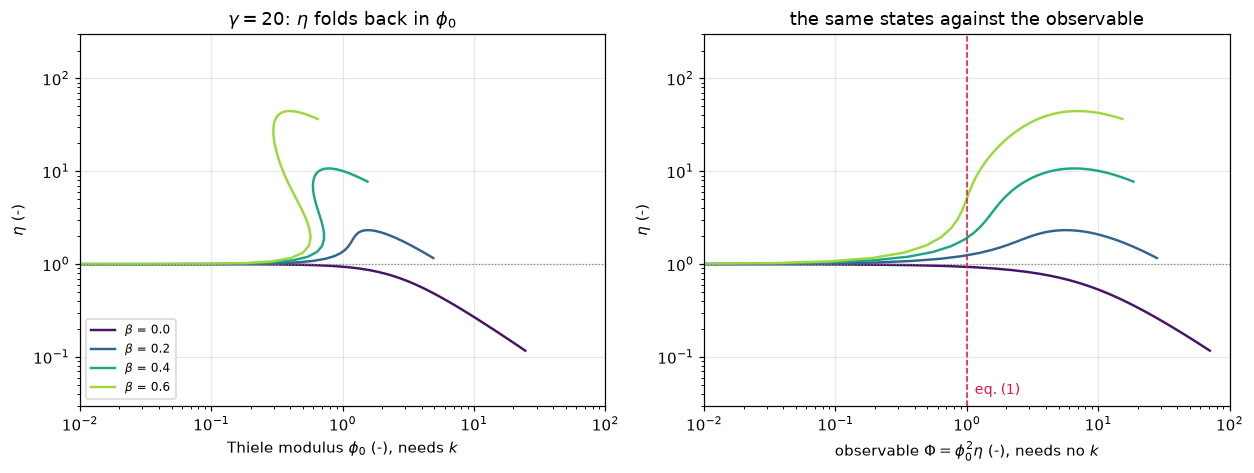

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
for c, beta in zip(plt.cm.viridis(np.linspace(0.05, 0.85, 4)), (0.0, 0.2, 0.4, 0.6)):
    br = BR[(beta, 20.0)]
    axes[0].loglog(br.phi, br.eta, color=c, lw=1.6, label=rf"$\beta$ = {beta}")
    axes[1].loglog(br.Phi, br.eta, color=c, lw=1.6)
axes[0].set_xlabel(r"Thiele modulus $\phi_0$ (-), needs $k$")
axes[1].set_xlabel(r"observable $\Phi = \phi_0^2\eta$ (-), needs no $k$")
for a in axes:
    a.set_ylabel(r"$\eta$ (-)"); a.set_ylim(3e-2, 3e2); a.set_xlim(1e-2, 1e2)
    a.axhline(1.0, color="0.5", lw=0.8, ls=":")
axes[1].axvline(1.0, color="crimson", lw=1.0, ls="--")
axes[1].text(1.15, 4e-2, "eq. (1)", color="crimson", fontsize=9)
axes[0].legend(fontsize=8, loc="lower left")
axes[0].set_title(r"$\gamma = 20$: $\eta$ folds back in $\phi_0$")
axes[1].set_title("the same states against the observable")
fig.tight_layout(); plt.show()

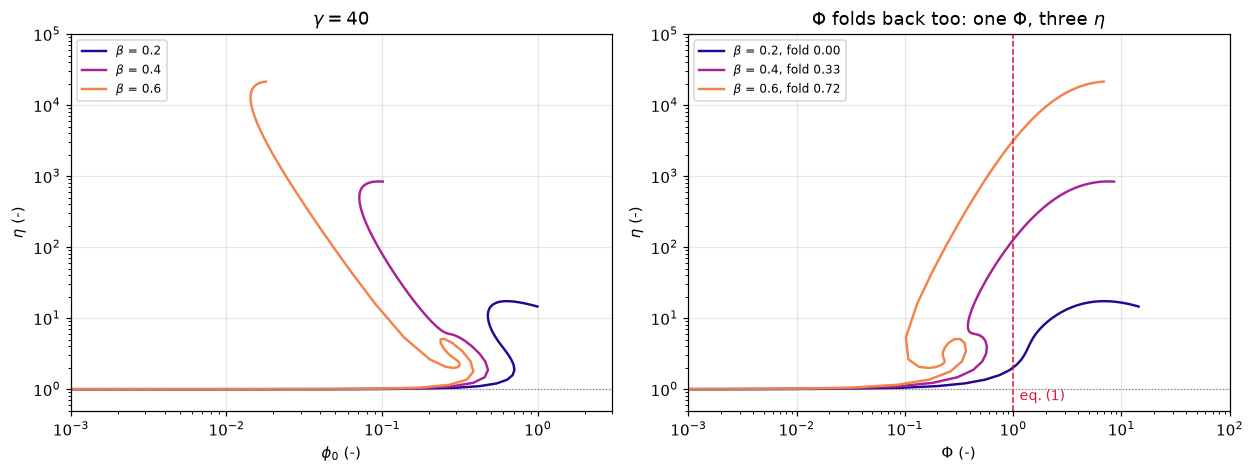

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
for c, beta in zip(plt.cm.plasma(np.linspace(0.05, 0.7, 3)), (0.2, 0.4, 0.6)):
    br = BR[(beta, 40.0)]
    axes[0].loglog(br.phi, br.eta, color=c, lw=1.6, label=rf"$\beta$ = {beta}")
    axes[1].loglog(br.Phi, br.eta, color=c, lw=1.6,
                   label=rf"$\beta$ = {beta}, fold {FOLD[(beta, 40.0)][1]:.2f}")
axes[0].set_xlabel(r"$\phi_0$ (-)"); axes[1].set_xlabel(r"$\Phi$ (-)")
for a in axes:
    a.set_ylabel(r"$\eta$ (-)"); a.axhline(1.0, color="0.5", lw=0.8, ls=":")
    a.legend(fontsize=8, loc="upper left"); a.set_ylim(0.5, 1e5)
axes[0].set_xlim(1e-3, 3.0)
axes[1].set_xlim(1e-3, 1e2)
axes[1].axvline(1.0, color="crimson", lw=1.0, ls="--")
axes[1].text(1.15, 0.7, "eq. (1)", color="crimson", fontsize=9)
axes[0].set_title(r"$\gamma = 40$")
axes[1].set_title(r"$\Phi$ folds back too: one $\Phi$, three $\eta$")
fig.tight_layout(); plt.show()

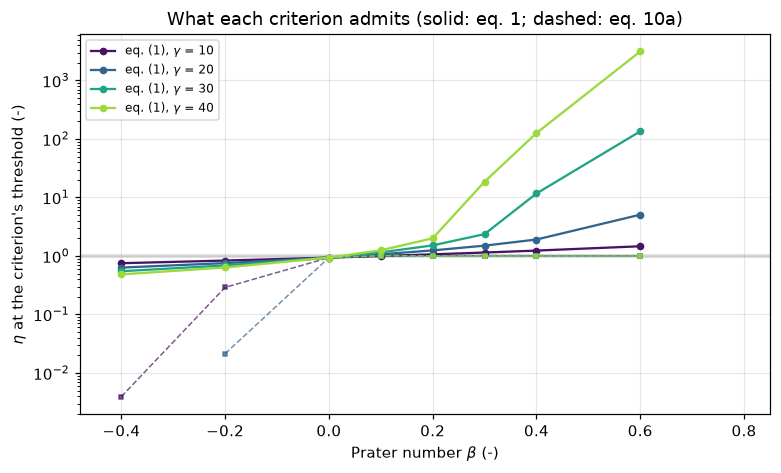

In [25]:
fig, ax = plt.subplots(figsize=(7.2, 4.4))
for c, gamma in zip(plt.cm.viridis(np.linspace(0.05, 0.85, 4)), GAMMAS):
    b = [k[0] for k in MAP if k[1] == gamma]
    e1 = [MAP[(x, gamma)]["eta_iso"] for x in b]
    e2 = [MAP[(x, gamma)]["eta_nis"] for x in b]
    ax.semilogy(b, e1, "o-", color=c, lw=1.5, ms=4, label=rf"eq. (1), $\gamma$ = {gamma:.0f}")
    ax.semilogy([x for x, v in zip(b, e2) if v], [v for v in e2 if v], "s--",
                color=c, lw=1.0, ms=3, alpha=0.7)
ax.axhspan(0.95, 1.05, color="0.85", zorder=0)
ax.set_xlabel(r"Prater number $\beta$ (-)"); ax.set_ylabel(r"$\eta$ at the criterion's threshold (-)")
ax.set_title("What each criterion admits (solid: eq. 1; dashed: eq. 10a)")
ax.legend(fontsize=8, loc="upper left")
ax.set_xlim(-0.48, 0.85)
fig.tight_layout(); plt.show()

## Validation

**Tier 6. Nothing on this page is compared with a measurement**, and none of
what follows is validation against experiment. What is available is a closed
form, a second numerical method, and printed numerical statements. Ranked,
strongest first:

1. **The shooting reference against the exact isothermal $\eta$**, three
   geometries, seven states each, on an integration-tolerance ladder. This is
   what licenses every branch result, because the branch tracer is the only
   route to the unstable middle branch.
2. **pymrm against the same closed form**, on a grid ladder, at the observed
   order of every case.
3. **pymrm against the shooting solution in the non-isothermal case**, over the
   whole branch including its unstable part, on a grid ladder. The two share
   only the rate law: one is a finite-volume solve in $u$, the other an
   initial-value integration in $s = \phi_0 u$.
4. **The threshold two ways**: a root scan on pymrm against the closed form;
   and, for the other kinetics, pymrm on every $\Phi = 1$ state the shooting
   branch contains.
5. **Printed statements reproduced**: the worked $\gamma = 20$, $\beta = 0.3$
   case giving $\phi_0 \sim 0.1$, the multiplicity onset at
   $\beta\gamma \gtrsim 5$, and $Q'/Q$ between 1 and $\tfrac12$. None is an
   input to anything.

Two checks look like evidence and are weaker. The observable computed as the
**volume average of the rate**, $\phi_0^2\langle\mathcal{R}\rangle$, against the
surface flux: `construct_div` is conservative, so the volume-weighted sum of the
residual telescopes to the surface flux and
$\Phi_{\text{flux}} - \Phi_{\text{volume}} = \frac{\nu+1}{V}\sum_i V_i\,\mathrm{res}_i$,
the solve residual again. It catches a solve that has not converged and a rate
that differs from the one used to interpret it; a wrong geometry index or a
coarse grid changes both sides alike. And a **converged residual** says the
equations are solved, not *which* solution was found: the second cell below
starts Newton from $y = 1$ on a folded branch.

In [26]:
ref = P800["sphere"]
PH_REF = TH["sphere"][0]
y_ref = ref.solve(PH_REF, R1)[0]
R_WH = WeiszHicks(0.3, 20.0)


def flux_vol_gap(pellet, model_rate, interp_rate=R1, maxfev=60):
    ph = PH_REF
    y = pellet.solve(ph, model_rate, maxfev=maxfev, check=maxfev > 1)[0]
    return abs(pellet.Phi(y) - pellet.Phi_from_volume(y, ph, interp_rate))


claims.bound("Phi_flux_minus_Phi_volume",
             max(flux_vol_gap(ref, R1), flux_vol_gap(ref, R_WH, R_WH)),
             max=1e-9, basis="tolerance", note="the volume-weighted residual of a newton solve, tol 1e-12, "
             "first order and the non-isothermal rate beta = 0.3, gamma = 20, both on the sphere at PH_REF")
print(f"first-order and non-isothermal (beta = 0.3, gamma = 20) sphere at the first-order threshold, "
      f"800 cells: Phi(flux) - Phi(volume) below 1e-9 (here {claims['Phi_flux_minus_Phi_volume']:.1e})")


brk("rate 1 % too large in the model (scale=1.01)", "Phi_flux_minus_Phi_volume",
    flux_vol_gap(ref, WeiszHicks(0.0, 20.0, scale=1.01)))
brk("newton stopped after one iteration (maxfev=1)", "Phi_flux_minus_Phi_volume",
    max(flux_vol_gap(ref, R1, maxfev=1), flux_vol_gap(ref, R_WH, R_WH, maxfev=1)))
brk("sphere assembled with nu = 0", "Phi_flux_minus_Phi_volume",
    flux_vol_gap(Pellet("sphere", 800, nu=0), R1))
brk("sphere on 3 cells", "Phi_flux_minus_Phi_volume", flux_vol_gap(Pellet("sphere", 3), R1))

first-order and non-isothermal (beta = 0.3, gamma = 20) sphere at the first-order threshold, 800 cells: Phi(flux) - Phi(volume) below 1e-9 (here 8.5e-12)


False

In [27]:
# A converged solve on a folded branch: the ignited state of beta = 0.6,
# gamma = 20, seeded from the shooting profile, and the same phi_0 from y = 1.
br_h = BR[(0.6, 20.0)]
tau_h = br_h.tau[np.argmax(br_h.eta)]
hard = Pellet("sphere", 800)
PHI_H, y_seed = br_h.profile(tau_h, hard.u_c)
R_H = WeiszHicks(0.6, 20.0)
ETA_H = shoot(2, R_H, np.exp(tau_h), rtol=1e-11)[1]


def ignited_gap(seed=True):
    y = hard.solve(PHI_H, R_H, y_init=y_seed if seed else None)[0]
    return abs(hard.eta(y, PHI_H) / ETA_H - 1)


claims.value("ignited_state_eta_pymrm_vs_shooting", ignited_gap(), rtol=1e-3)
brk("newton started from y = 1 instead of the shooting profile", "ignited_state_eta_pymrm_vs_shooting",
    ignited_gap(seed=False))
y_cold, sol_cold = hard.solve(PHI_H, R_H)
n_here = (sum(int((a - PHI_H) * (b - PHI_H) < 0) for a, b in zip(br_h.phi[:-1], br_h.phi[1:]))
          + int(np.sum(br_h.phi == PHI_H)))   # PHI_H is itself a traced state
print(f"beta = 0.6, gamma = 20, phi_0 = {PHI_H:.5f}: the branch carries {n_here} steady states here.")
print(f"  seeded from the shooting profile: eta = {hard.eta(hard.solve(PHI_H, R_H, y_init=y_seed)[0], PHI_H):.5f}"
      f" (shooting {ETA_H:.5f})")
print(f"  started from y = 1             : eta = {hard.eta(y_cold, PHI_H):.5f}, newton '{sol_cold.message}'"
      f" (here {sol_cold.nit} iterations)")
print("Both solves converge; the cold one found another solution of the same equations.")
print("Only the branch trace says which, which is why every multiplicity result here is")
print("located on the shooting branch first.")

beta = 0.6, gamma = 20, phi_0 = 0.39677: the branch carries 3 steady states here.
  seeded from the shooting profile: eta = 44.55472 (shooting 44.55465)
  started from y = 1             : eta = 1.15529, newton 'Converged' (here 4 iterations)
Both solves converge; the cold one found another solution of the same equations.
Only the branch trace says which, which is why every multiplicity result here is
located on the shooting branch first.


### The break table

Every number above is registered as a claim; each row below injects one defect
through an argument or a parameter and reports what the claim becomes, and
whether the claim's own check catches it. Rows that a claim does not catch are
kept: they show what that check is blind to.

In [28]:
print(f"{'injected defect':<74} {'claim':<40} {'clean':>11} {'broken':>16}  caught")
for name, metric, clean, broken, caught in BREAK:
    is_bound = claims.metrics[metric]["kind"] == "bound"
    shown = f"(here {clean:.0e})" if is_bound else f"{float(clean):11.4g}"
    print(f"{name[:74]:<74} {metric[:40]:<40} {shown:>11} {'(here %.3g)' % float(broken):>16}  "
          f"{'yes' if caught else 'NO'}")
_caught = {m for _, m, _, _, c in BREAK if c}
_structural = sorted(k for k, c in claims.metrics.items() if c.get("structural"))
_open = sorted(k for k in claims.metrics if k not in _caught and k not in _structural)
print(f"\n{len(BREAK)} rows; {len(_caught)} of {len(claims.metrics)} claims are failed by at "
      f"least one row; structural: {', '.join(_structural) or 'none'}; "
      f"open: {', '.join(_open) or 'none'}")
_uncaught = [(n, m) for n, m, _, _, c in BREAK if not c]
print("rows that do not fail their claim: "
      + ("; ".join(f"{n} -> {m}" for n, m in _uncaught) or "none"))

injected defect                                                            claim                                          clean           broken  caught
Phi read by a two-point gradient from the last cell centre (two_point=True surface_gradient_cbv_vs_operator_row     (here 0e+00)  (here 0.000701)  yes
Jacobian by NumJac differencing (jacobian='numjac')                        cold_scan_failed_solves_exact_jacobian            13        (here 18)  yes
eq. (10) exponent without its 1 + beta (denominator=False)                 eq10_worked_case_phi0                        0.09949    (here 0.0498)  yes
shooting integrated at rtol 1e-6                                           shooting_vs_exact_isothermal_eta         (here 8e-11)  (here 8.71e-06)  yes
Phi read by a two-point gradient from the last cell centre (two_point=True pymrm_vs_exact_isothermal_eta_n400         8.311e-06   (here 0.00617)  yes
Phi read by a two-point gradient from the last cell centre (two_point=True pymrm_vs_exact_order

## What pymrm adds

**Nothing to the criterion, which is one line of algebra**, and nothing to
Weisz and Hicks' extension of it; both are reproduced as printed. What the page
adds is the part the sources leave as an order of magnitude, computed with two
independent solvers that agree to the levels printed above. pymrm supplies one
of them: the finite-volume pellet with operators assembled once, an exact
Jacobian through `construct_coefficient_matrix`, `newton` with bounds, the
surface gradient through `compute_boundary_values`, and the root scans of
`pymrm.checks.find_roots`. The other, the shooting branch tracer, uses SciPy
integration and a generic root scan (`find_roots`), independent of pymrm's
discretisation, and it carries every multiplicity result; pymrm's role there is to
confirm the traced states on a grid.

In [29]:
display(Markdown(f"""
- **The threshold's guarantee, as a number.** $\\Phi < 1$ admits
  $\\eta = {claims['eta_at_Phi1_sphere_first_order']:.4f}$ for a first-order sphere and
  ${claims['eta_at_Phi1_slab_first_order']:.4f}$ for a slab. Measured on the
  volume-to-surface length instead, the spread across geometries falls from
  ${claims['eta_at_Phi1_spread_on_R']:.3f}$ to ${claims['eta_at_Phi1_spread_on_VS']:.3f}$.
  Across kinetics on one shape the guarantee runs from exactly 1 (zero order)
  through ${claims['eta_at_Phi1_second_order']:.4f}$ (second order) to
  ${claims['eta_at_Phi1_inhibited_LH']:.4f}$ for a self-inhibited Langmuir-Hinshelwood
  rate, above 1 with no heat effect.
- **Where the isothermal form fails, quantified.** For an exothermic pellet eq. (1)
  admits $\\eta$ up to ${claims['eta_at_Phi1_worst_exothermic']:.4g}$. Eq. (10a) passes
  {claims['fn_eq10a_exothermic']} of the unclean measurements here and holds $\\eta$ within
  ${100 * claims['eq10a_worst_eta_deviation_exothermic']:.1f}$ % of 1 at its threshold, paying
  with a conservatism up to a factor ${claims['eq10a_max_conservatism']:.3g}$ in $\\Phi$.
- **The endothermic case, where the extension inverts.** Its threshold exceeds 1;
  it is reached only at $\\eta \\le {claims['eq10a_endothermic_eta_at_threshold_max']:.3g}$,
  so eq. (10a) passes {claims['fn_eq10a_endothermic']} of the
  {claims['not_clean_endothermic']} unclean endothermic measurements.
- **A quantitative limit on the Section V claim.** The observable postpones the
  multiplicity, from $\\beta\\gamma = {claims['multiplicity_onset_betagamma_min']:.2f}$ to
  ${claims['multiplicity_onset_betagamma_max']:.2f}$ in $\\phi_0$ to
  ${claims['observable_fold_onset_betagamma_min']:.2f}$ to
  ${claims['observable_fold_onset_betagamma_max']:.2f}$ in $\\Phi$; $\\Phi$ is multivalued in
  {claims['Phi_multivalued_cases']} of the 32 swept cases, inside the range the paper
  says it computed.
- **Every fold sits below $\\Phi = 1$** (largest turning point
  ${claims['observable_fold_turning_point_Phi_max']:.4f}$), inside the band the criterion
  certifies as safe; $\\Phi = 1$ keeps a unique root in {claims['Phi1_unique_root_cases']} of 32.
  {claims['ambiguous_measurements']} measurements on this page's grid fit more than one state, the
  worst with an $\\eta$ spread of a factor ${claims['ambiguous_measurement_worst_eta_spread']:.1f}$.
- **What Fig. 7 can settle, in pixels.** {claims['fig7_panels_with_folded_curve']} of its four
  panels draws a curve in the folded regime; that fold spans
  ${claims['fig7d_fold_width_px_at_600dpi']:.1f}$ px at 600 dpi against a 6 to 7 px stroke, so the
  figure is silent. A limit on the claim, not a refutation: the criterion works
  everywhere the authors apply it.
"""))


- **The threshold's guarantee, as a number.** $\Phi < 1$ admits
  $\eta = 0.9353$ for a first-order sphere and
  $0.6948$ for a slab. Measured on the
  volume-to-surface length instead, the spread across geometries falls from
  $0.240$ to $0.132$.
  Across kinetics on one shape the guarantee runs from exactly 1 (zero order)
  through $0.8796$ (second order) to
  $1.0483$ for a self-inhibited Langmuir-Hinshelwood
  rate, above 1 with no heat effect.
- **Where the isothermal form fails, quantified.** For an exothermic pellet eq. (1)
  admits $\eta$ up to $3136$. Eq. (10a) passes
  0 of the unclean measurements here and holds $\eta$ within
  $1.3$ % of 1 at its threshold, paying
  with a conservatism up to a factor $1.01e+05$ in $\Phi$.
- **The endothermic case, where the extension inverts.** Its threshold exceeds 1;
  it is reached only at $\eta \le 0.29$,
  so eq. (10a) passes 369 of the
  384 unclean endothermic measurements.
- **A quantitative limit on the Section V claim.** The observable postpones the
  multiplicity, from $\beta\gamma = 4.91$ to
  $5.56$ in $\phi_0$ to
  $10.84$ to
  $21.74$ in $\Phi$; $\Phi$ is multivalued in
  4 of the 32 swept cases, inside the range the paper
  says it computed.
- **Every fold sits below $\Phi = 1$** (largest turning point
  $0.8055$), inside the band the criterion
  certifies as safe; $\Phi = 1$ keeps a unique root in 32 of 32.
  14 measurements on this page's grid fit more than one state, the
  worst with an $\eta$ spread of a factor $100.7$.
- **What Fig. 7 can settle, in pixels.** 1 of its four
  panels draws a curve in the folded regime; that fold spans
  $6.9$ px at 600 dpi against a 6 to 7 px stroke, so the
  figure is silent. A limit on the claim, not a refutation: the criterion works
  everywhere the authors apply it.


## Reuse

| Change | Where |
|---|---|
| Different geometry | `Pellet(geom=...)`, or a callable `nu` in `construct_div` |
| Different kinetics | any object with `r(y)` and `dr(y)`; `jacobian="numjac"` if `dr` is not available |
| Your own measurement | `Branch(nu, rate).all_where(lambda p, e, P: P - your_Phi)`: the inversion needs no $k$, and it returns *every* consistent state |
| Non-isothermal | `WeiszHicks(beta, gamma)`, the reduced eq. (9) |
| Two fields instead of one | [`B1.6`](../B1.6-prater-relation/)'s two-field pellet, if you do not want the Prater relation substituted |
| The unstable branch | `Branch`, parametrised by $y_c$, not $\phi_0$; `Branch.profile` seeds `Pellet.solve` there |

**How to use the criterion, given what is above.** Compute
$\Phi = r_{\mathrm{obs}}L^2/(D_ec_s)$ and **state the length scale**: the
threshold and the length are not separable, and quoting $\Phi < 1$ without
saying whether $L$ is $R$ or $V/S$ leaves a factor $(\nu+1)^2 = 9$ on a sphere.
If the reaction is exothermic, estimate $\beta$ and $\gamma$ and use eq. (10a),
not eq. (1). If $\beta\gamma$ is above the onsets printed in the fold section,
the observable may no longer determine the state. And a passing $\Phi$ still
admits several per cent in $\eta$ and in the apparent activation energy; the
threshold section prints both, per geometry.

**Reading Weisz and Hicks.** The scan's text layer is unusable for equations.
Render the journal page at 600 dpi and read it. Same trap as `B3.1` and `B1.6`,
recorded in `docs/pdf-findings.md`.

**Related pages.** [`B1.1`/`B1.5`](../B1.1-thiele-weisz-hicks/), the forward
problem $\eta(\phi_0)$ and the multiplicity this page views through the
observable; [`B1.6`](../B1.6-prater-relation/), the Prater relation that
reduces the two balances to the one equation used here; `B1.2` Aris generalised
modulus and `B1.3` Bischoff generalised modulus, the length-scale question;
`B1.7` Mears criteria, the same observable-only logic for external gradients.

## References

Weisz, P. B. and Prater, C. D. (1954). In *Advances in Catalysis*, Vol. 6,
p. 143. Academic Press, New York. **The origin the criterion is named for; not
consulted**, no copy on disk and no open-access route. Given as Weisz and
Hicks' reference [5] prints it on journal page 274, with **no chapter title**.

Weisz, P. B. (1957). *Z. Phys. Chem.* **11**, 1. The reference Weisz and Hicks
attach to eq. (1). **Not consulted.**

Weisz, P. B. and Hicks, J. S. (1962). *The behaviour of porous catalyst
particles in view of internal mass and heat diffusion effects.* Chemical
Engineering Science **17**(4), 265-275.
[doi:10.1016/0009-2509(62)85005-2](https://doi.org/10.1016/0009-2509(62)85005-2).
**The source actually read**: eqs. (1), (9), (10), (10a) and (11), the $Q'/Q$
relation, the $\beta\gamma \gtrsim 5$ statement and the Section V claim from
600 dpi renders of journal pages 265, 267, 268, 269, 272 and 273; the two
references above from page 274; the Fig. 7(d) axis calibration and stroke width
from the render of page 272.

In [30]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for B1.4:
  surface_gradient_cbv_vs_operator_row       = (here 0.0e+00)   bound  bound <= 1e-12 [identity]
  cold_scan_failed_solves_exact_jacobian     = 13               exact  exact
  eq10_worked_case_phi0                      = 0.099491         value  rtol 1e-06
  shooting_vs_exact_isothermal_eta           = (here 8.4e-11)   bound  bound <= 1e-09 [tolerance]
  pymrm_vs_exact_isothermal_eta_n400         = 8.3106e-06       value  rtol 0.001
  pymrm_vs_exact_order_min                   = (here 2.0e+00)   bound  bound [1.9, 3.1] [chosen]
  pymrm_vs_exact_order_max                   = (here 3.0e+00)   bound  bound [1.9, 3.1] [chosen]
  pymrm_vs_exact_finest_over_roundoff_min    = (here 1.0e+05)   bound  bound >= 1000 [theory]
  pymrm_vs_shooting_nonisothermal_n800       = 5.0157e-05       value  rtol 0.001
  pymrm_vs_shooting_order_min                = (here 2.0e+00)   bound  bound [1.9, 2.1] [theory]
  pymrm_vs_shooting_order_max                = (here 2.0e+00)   bound  bound [1.